# Analyse modale

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la
from scipy.integrate import odeint
import scipy.fftpack
from scipy import signal
plt.rcParams['figure.figsize'] = [12, 3]
from scipy import optimize
import functools
from matplotlib import cm
from matplotlib.ticker import LinearLocator, FormatStrFormatter
from mpl_toolkits.mplot3d import axes3d, Axes3D #<-- Note the capitalization! 

## Paramètres de la poutre

In [2]:
n_elem=3; # nombre d'éléments --> NE PAS MODIFIER
E=210000000000; # module d'Young --> A MODIFIER
rho=7800; # masse volumique --> A MODIFIER
e=0.002; # épaisseur de la lame --> A MODIFIER
b=0.015; # largeur de la lame --> A MODIFIER
l=0.3; # longueur de la lame --> A MODIFIER
alpha=20;
ksi_rayleigh=0.01; # taux d'amortissement (visqueux) de la lame --> A MODIFIER
S=e*b; # Section de la poutre
x=np.linspace(0,l,101); # Coordonnées le long de la poutre

## Construction des matrices du système

\begin{equation}
\left[ M \right] \left\lbrace \ddot{q} \right\rbrace + \left[ B \right] \left\lbrace \dot{q} \right\rbrace + \left[ K \right] \left\lbrace q \right\rbrace = \left\lbrace 0 \right\rbrace
\end{equation}

\begin{equation}
\left[ M^e \right] =
\frac{\rho S l}{420} \left[ \begin{array}{c c c c}
156 & 22 l & 54 & -13 l \\
22 l & 4 l^2 & 13 l & -3 l^2  \\
54 & 13 l & 156 & -22 l \\
-13 l & -3 l^2 & -22 l & 4 l^2
\end{array} \right]
\end{equation}

\begin{equation}
\left[ K^e \right] =
\frac{EI}{l^3} \left[ \begin{array}{c c}
12 & 6 l & -12 & 6 l \\
6 l & 4 l^2 & -6 l & 2 l^2 \\
-12 & -6 l & 12 & -6 l \\
6 l & 2 l^2 & -6 l & 4 l^2
\end{array} \right]
\end{equation}

In [3]:
l_elem=l/n_elem; # longueur d'un élément
I=(b*e**3)/12;
k_elem=E*I/(l_elem**3)*np.array([[12,6*l_elem,-12,6*l_elem],[6*l_elem,4*l_elem**2,-6*l_elem,2*l_elem**2],[-12,-6*l_elem,12,-6*l_elem],[6*l_elem,2*l_elem**2,-6*l_elem,4*l_elem**2]]);
m_elem=rho*S*l_elem*np.array([[1/2,0,0,0],[0,1/210*l_elem**2,0,0],[0,0,1/2,0],[0,0,0,1/210*l_elem**2]]);
#m_elem=rho*S*l_elem/420*np.array([[156,22*l_elem,54,-13*l_elem],[22*l_elem,4*l_elem**2,13*l_elem,-3*l_elem**2],[54,13*l_elem,156,-22*l_elem],[-13*l_elem,-3*l_elem**2,-22*l_elem,4*l_elem**2]]);
k_ass0=np.zeros((2*(n_elem+1),2*(n_elem+1)));
m_ass0=np.zeros((2*(n_elem+1),2*(n_elem+1)));

for j in range(n_elem):
    k_ass0[2*j:2*j+4,2*j:2*j+4]=k_ass0[2*j:2*j+4,2*j:2*j+4]+k_elem;
    m_ass0[2*j:2*j+4,2*j:2*j+4]=m_ass0[2*j:2*j+4,2*j:2*j+4]+m_elem;

b_ass0=alpha*m_ass0;
kk=k_ass0[2:2*(n_elem+1),2:2*(n_elem+1)];
mm=m_ass0[2:2*(n_elem+1),2:2*(n_elem+1)];
bb=b_ass0[2:2*(n_elem+1),2:2*(n_elem+1)];

#print("k_elem",k_elem);
#print("k_ass0 =",k_ass0);
#print("kk =",kk);
#print("m_elem =",m_elem);
#print("m_ass0 =",m_ass0);
#print("mm =",mm);
#print("b_ass0 =",b_ass0);
#print("bb =",bb);

## Réécriture du problème (prise en compte de l'amortissement)

\begin{equation}
\left[ \begin{array}{c c} \left[ 0 \right] & \left[ M \right] \\ \left[ M \right] & \left[ B \right] \end{array} \right] \left\lbrace \begin{array}{c} \left\lbrace \ddot{q} \right\rbrace \\ \left\lbrace \dot{q} \right\rbrace \end{array} \right\rbrace + \left[ \begin{array}{c c} \left[ -M \right] & \left[ 0 \right] \\ \left[ 0 \right] & \left[ K \right] \end{array} \right] \left\lbrace \begin{array}{c} \left\lbrace \dot{q} \right\rbrace \\ \left\lbrace q \right\rbrace \end{array} \right\rbrace = \left\lbrace \begin{array}{c} \left\lbrace 0 \right\rbrace \\ \left\lbrace 0 \right\rbrace \end{array} \right\rbrace
\end{equation}

In [4]:
ms1=np.concatenate((np.zeros(mm.shape), mm), axis=0);
ms2=np.concatenate((mm, bb), axis=0);
ms=np.concatenate((ms1, ms2), axis=1);
ks1=np.concatenate((-mm, np.zeros(mm.shape)), axis=0);
ks2=np.concatenate((np.zeros(mm.shape), kk), axis=0);
ks=np.concatenate((ks1, ks2), axis=1);

#print("ms =",ms)
#print("ks =",ks)

## Pulsations et modes analytiques

\begin{equation}
\omega_{1} = 1.87^2 \sqrt{\frac{EI}{m l^3}}
\end{equation}

$k \in \mathbb{N}^{*} (>1)$,
\begin{equation}
\omega_{k} = \left( (2k-1) \frac{\pi}{2} \right)^2 \sqrt{\frac{EI}{m l^3}}
\end{equation}

\begin{equation}
\phi_{k}(x)=C_{1,k} \, \left( cos(\alpha_{k}(x))-ch(\alpha_{k}(x)) \right) + \frac{sin(\alpha_{k}(l))-sh(\alpha_{k}(l))}{cos(\alpha_{k}(l))+ch(\alpha_{k}(l))}\left( sin(\alpha_{k}(x))-sh(\alpha_{k}(x)) \right)
\end{equation}

Avec,
\begin{equation}
\alpha_{k}(x)=\sqrt[4]{\omega_{k}^2 \frac{\rho S}{E I}x}
\end{equation}

In [5]:
omega_ana=np.zeros((2*n_elem,1));
alpha_l=np.zeros((2*n_elem,1));
Phi_ana=np.zeros((2*n_elem,len(x)));

for k in range(2*n_elem):
    omega_ana[k]=((2*(k+1)-1)*np.pi/2)**2*np.sqrt(E*I/rho/S/l/(l**3));
    if k==0:
        omega_ana[k]=(1.87)**2*np.sqrt(E*I/rho/S/l/(l**3));
    print("omega",k+1,"=", omega_ana[k]);
    alpha_l[k]=(omega_ana[k]**2*rho*S/E/I)**(1/4)*l;
    for j in range(len(x)):
        temp=(omega_ana[k]**2*rho*S/E/I)**(1/4)*x[j];
        Phi_ana[k,j]=(np.cos(temp)-np.cosh(temp))+(np.sin(alpha_l[k])-np.sinh(alpha_l[k]))/(np.cos(alpha_l[k])+np.cosh(alpha_l[k]))*(np.sin(temp)-np.sinh(temp));

omega 1 = [116.39717026]
omega 2 = [739.16513307]
omega 3 = [2053.23648074]
omega 4 = [4024.34350225]
omega 5 = [6652.4861976]
omega 6 = [9937.66456678]


## Résolution du problème aux valeurs propres pour résultats de référence

pulsations propres (desordre) :
******************************
pulsations propres (ordre) :
omegar_ = [  110.66112185   621.43511586  1549.83226673  6576.94140971
  8774.72514947 10467.20675815]
fr = [  17.61226455   98.9044705   246.66346621 1046.75273578 1396.54088181
 1665.90769592]
******************************
amortissements modaux (ordre) :
br_ = [0.08999925 0.0160897  0.00645218 0.00152046 0.00113964 0.00095536]
******************************
modes propres (ordre) :
vps = [[ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 2.25462745e-02 -3.00308001e-02 -4.07466199e-02 -8.17652131e-04
  -3.69949207e-05  3.02671400e-04]
 [ 4.12501415e-01 -3.21362997e-01  1.22260415e-01  3.68797529e-01
  -7.22061213e-01  3.31780776e-01]
 [ 7.53053881e-02 -2.93068132e-02  2.85614390e-02  4.57613170e-04
   1.03138075e-03  2.05695379e-04]
 [ 6.09426

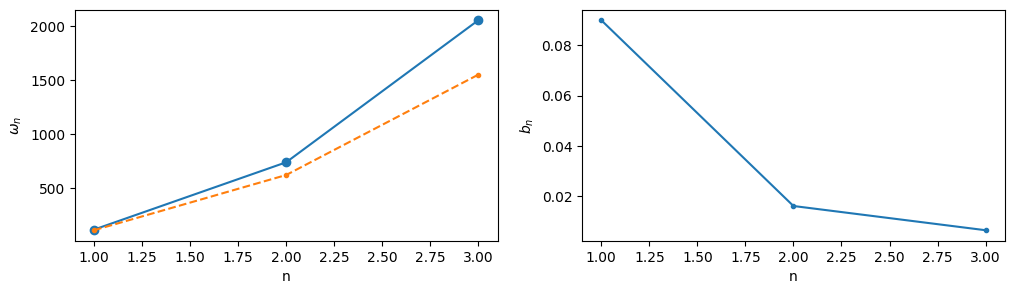

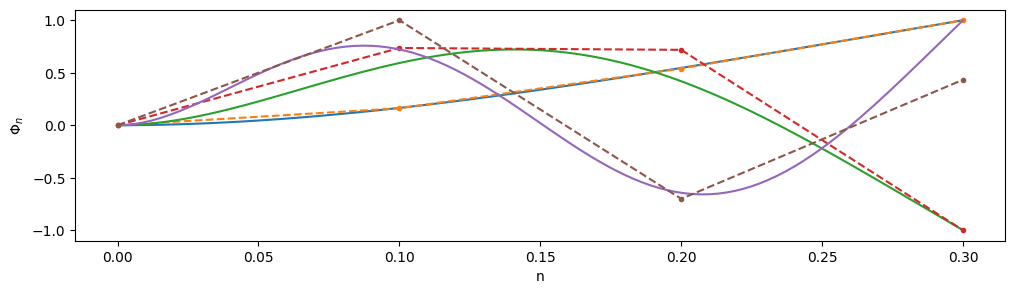

In [6]:
val_propres, vect_propres = la.eig(-np.dot(la.inv(ms),ks));
#print("val_propres =", val_propres)
#print("vect_propres =", vect_propres)

omegar=np.imag(val_propres);
o_omegar=np.argsort(omegar);
#print("o_omegar =",o_omegar);
print("pulsations propres (desordre) :");
#print("omegar =",omegar);
print("******************************");
print("pulsations propres (ordre) :");
omegar_=omegar[o_omegar][2*n_elem:4*n_elem:1];
print("omegar_ =",omegar_);
print("fr =",omegar_/2/np.pi);
#print("******************************");
#print("amortissements modaux (desordre) :");
br=-np.real(val_propres)/np.abs(val_propres);
#print("br",br);
print("******************************");
print("amortissements modaux (ordre) :");
br_=br[o_omegar][2*n_elem:4*n_elem:1];
print("br_ =",br_);
#print("******************************");
#print("modes propres (desordre) :");
#print("vps =",vect_propres);
vps_=np.real(vect_propres[0:2*n_elem,o_omegar][:,2*n_elem:4*n_elem:1]);
vps=np.concatenate((np.zeros((2,2*n_elem)),vps_), axis=0);
print("******************************");
print("modes propres (ordre) :");
print("vps =",vps);
plt.figure();
plt.subplot(1,2,1);
plt.plot(range(1,4),omega_ana[0:3],'-o');
plt.plot(range(1,4),omegar_[0:3],'.--');
plt.xlabel("n");
plt.ylabel("$\omega_{n}$");
plt.subplot(1,2,2);
plt.plot(range(1,4),br_[0:3],'.-');
plt.xlabel("n");
plt.ylabel("$b_{n}$");
plt.figure();
for i in range(3):
    plt.plot(x,Phi_ana[i,:]/np.max(np.abs(Phi_ana[i,:]))*np.sign(Phi_ana[i,1]),'-');
    plt.plot(np.arange(0,n_elem+1,1)/(n_elem)*l,vps[0:2*n_elem+1:2,i]/np.max(np.abs(vps[0:2*n_elem+1:2,i]))*np.sign(vps[2,i]),'.--');
plt.xlabel("n");
plt.ylabel("$\Phi_{n}$");

## Définition de l'excitation (impulsion)

[0.0000e+00 1.0000e-03 2.0000e-03 ... 5.9997e+01 5.9998e+01 5.9999e+01]
[   0. 1000.    0. ...    0.    0.    0.]


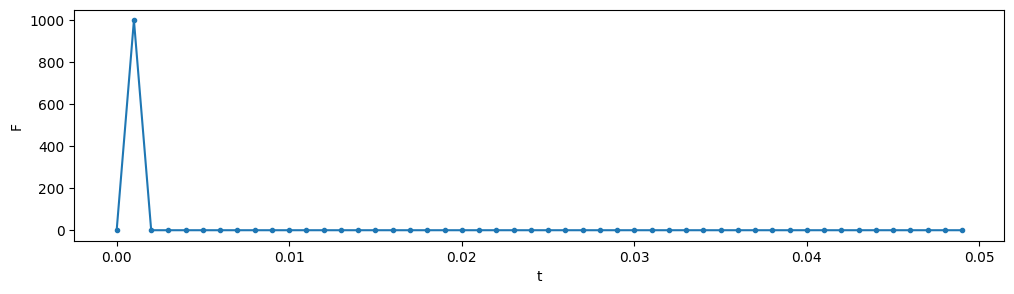

In [132]:
hh=0.001;
tt=np.arange(0,60,hh);
def force(t):
    tmax=hh;
    Fmax=1/tmax;
    if t<=tmax :
        f=t*Fmax/tmax;
    elif (t>tmax)and(t<=2*tmax) :
        f=-Fmax/tmax*t+2*Fmax;
    else :
        f=0
    return f

ff=np.zeros(tt.shape)
for ii in range(len(tt)):
    ff[ii]=force(tt[ii]);
    
plt.plot(tt[0:50],ff[0:50],'.-');
##plt.plot(tt, ff)
plt.xlabel('t');
plt.ylabel('F');
print(tt)
print(ff)

## Calcul des signaux temporels

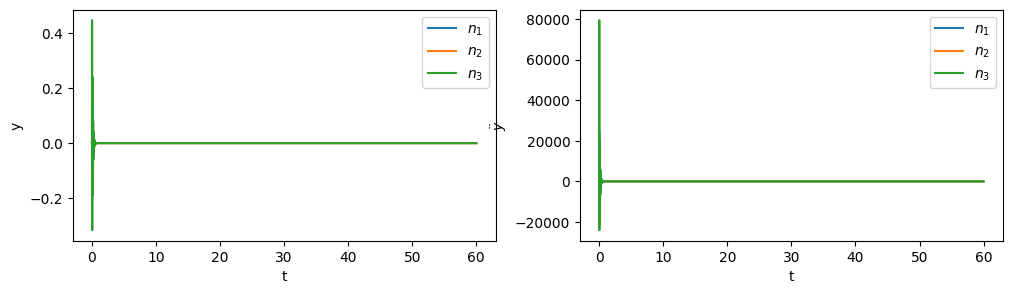

In [123]:
def cauchy(y,t):
    ydot=np.zeros(y.shape);
    ydot[0]=y[1];
    ydot[1]=(-bb[0,0]*y[1]-kk[0,0]*y[0]-kk[0,1]*y[2]-kk[0,2]*y[4]-kk[0,3]*y[6])/mm[0,0];
    #ydot[1]=(-bb[0,0]*y[1]-np.vdot(kk[0,:],y[0:11:2]))/mm[0,0];

    ydot[2]=y[3];
    ydot[3]=(-bb[1,1]*y[3]-kk[1,0]*y[0]-kk[1,1]*y[2]-kk[1,2]*y[4]-kk[1,3]*y[6])/mm[1,1];
    #ydot[3]=(-bb[1,1]*y[3]-np.vdot(kk[1,:],y[0:11:2]))/mm[1,1];

    ydot[4]=y[5];
    ydot[5]=(-bb[2,2]*y[5]-kk[2,0]*y[0]-kk[2,1]*y[2]-kk[2,2]*y[4]-kk[2,3]*y[6]-kk[2,4]*y[8]-kk[2,5]*y[10])/mm[2,2];
    #ydot[5]=(-bb[2,2]*y[5]-np.vdot(kk[2,:],y[0:11:2]))/mm[2,2];

    ydot[6]=y[7];
    ydot[7]=(-bb[3,3]*y[7]-kk[3,0]*y[0]-kk[3,1]*y[2]-kk[3,2]*y[4]-kk[3,3]*y[6]-kk[3,4]*y[8]-kk[3,5]*y[10])/mm[3,3];
    #ydot[7]=(-bb[3,3]*y[7]-np.vdot(kk[3,:],y[0:11:2]))/mm[3,3];

    ydot[8]=y[9];
    ydot[9]=(force(t)-bb[4,4]*y[9]-kk[4,2]*y[4]-kk[4,3]*y[6]-kk[4,4]*y[8]-kk[4,5]*y[10])/mm[4,4];
    #ydot[9]=(force(t)-bb[4,4]*y[9]-np.vdot(kk[4,:],y[0:11:2]))/mm[4,4];

    ydot[10]=y[11];
    ydot[11]=(-bb[5,5]*y[11]-kk[5,2]*y[4]-kk[5,3]*y[6]-kk[5,4]*y[8]-kk[5,5]*y[10])/mm[5,5];
    #ydot[11]=(-bb[5,5]*y[11]-np.vdot(kk[5,:],y[0:11:2]))/mm[5,5];

    return ydot

y0=np.array([0,0,0,0,0,0,0,0,0,0,0,0]);
yode=odeint(cauchy,y0,tt);

ydot=np.zeros(yode.shape);
for ii in range(len(tt)):
    ydot[ii,:]=cauchy(yode[ii,:],tt[ii]);

plt.figure();
plt.subplot(1,2,1);
plt.plot(tt[:],yode[:,0:11:4]);
plt.xlabel("t");
plt.ylabel("y");
plt.legend(['$n_{1}$','$n_{2}$','$n_{3}$'])

plt.subplot(1,2,2);
plt.plot(tt[:],ydot[:,1:11:4]);
plt.xlabel("t");
plt.ylabel("$\ddot{y}$");
plt.legend(['$n_{1}$','$n_{2}$','$n_{3}$'])

[ 0.00000000e+00 -2.66977786e+03 -7.49305852e+03 ...  9.42038773e-06
 -4.75360294e-06 -6.18294410e-06]


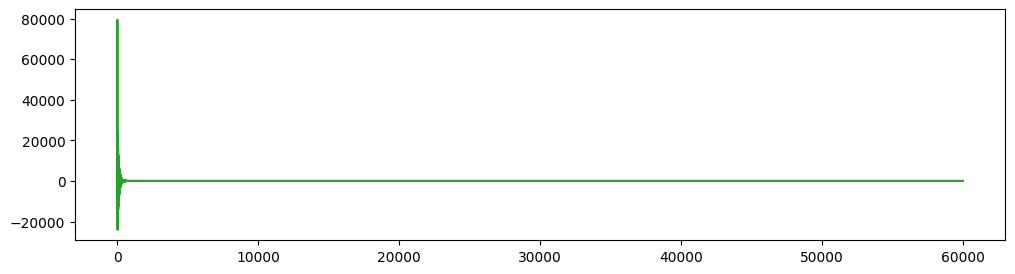

In [124]:

plt.plot(ydot[:, 1])
plt.plot(ydot[:, 5])
plt.plot(ydot[:, 9])
print(ydot[:, 1])

## Import des données réelles

out
out
out
64951 64951 64951


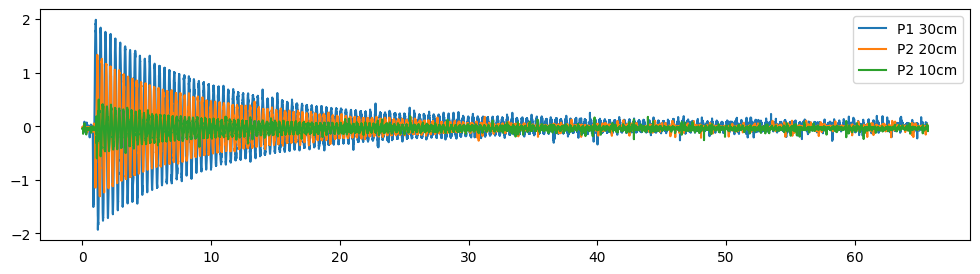

In [41]:
import csv 
P1FRF_data = []
P2FRF_data = []
P3FRF_data = []

def extract_table(dt, index):
	"""
	Description :
	A partir d'une table de données traitées et complète, produit une table de donnée d'un seul paramètre. 

	Paramètres :
	- dt : Data Table.
	- index : la position de l'information dans une ligne de données.

	Retour :
	Table de données d'un seul type.
	"""
	ndt = [0]*len(dt)
	for i in range(len(dt)):
		ndt[i] = dt[i][index]
	return ndt
 

with open('Measurements/P1FRF.csv') as csv_file:
    csv_reader = csv.reader(csv_file, delimiter=';')
    line_count = 0
    for row in csv_reader:
        P1FRF_data.append([float(row[0]), float(row[1])])
    print("out")
with open('Measurements/P2FRF.csv') as csv_file:
    csv_reader = csv.reader(csv_file, delimiter=';')
    line_count = 0
    for row in csv_reader:
        P2FRF_data.append([float(row[0]), float(row[1])])
    print("out")
with open('Measurements/P3FRF.csv') as csv_file:
    csv_reader = csv.reader(csv_file, delimiter=';')
    line_count = 0
    for row in csv_reader:
        P3FRF_data.append([float(row[0]), float(row[1])])
    print("out")


print(len(P1FRF_data), len(P2FRF_data), len(P3FRF_data))
plt.plot(extract_table(P1FRF_data, 0), extract_table(P1FRF_data, 1), label = "P1 30cm")
plt.plot(extract_table(P2FRF_data, 0), extract_table(P2FRF_data, 1), label = "P2 20cm")
plt.plot(extract_table(P3FRF_data, 0), extract_table(P3FRF_data, 1), label = "P2 10cm")

plt.legend()


(60000,)


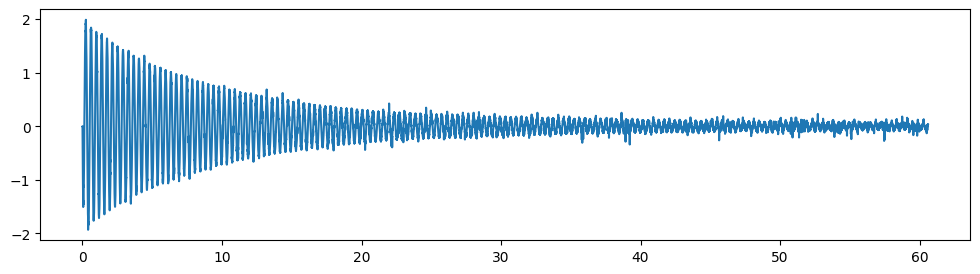

In [66]:
## Rabottage

#for i in range(0,len(P1FRF_data)):
    #print(i, ":", P1FRF_data[i])

P1FRF_new_data = P1FRF_data[785:60785]

P1_new_initial_time = P1FRF_new_data[0][0]
for j in range(0, len(P1FRF_new_data)):
    P1FRF_new_data[j][0] -= P1_new_initial_time
    P1FRF_new_data[j][0] = round(P1FRF_new_data[j][0],5)


plt.plot(extract_table(P1FRF_new_data, 0), extract_table(P1FRF_new_data, 1), label = "P1 30cm")
P1FRF_new_data = np.array(extract_table(P1FRF_new_data, 1))

print(P1FRF_new_data.shape)

(60000,)


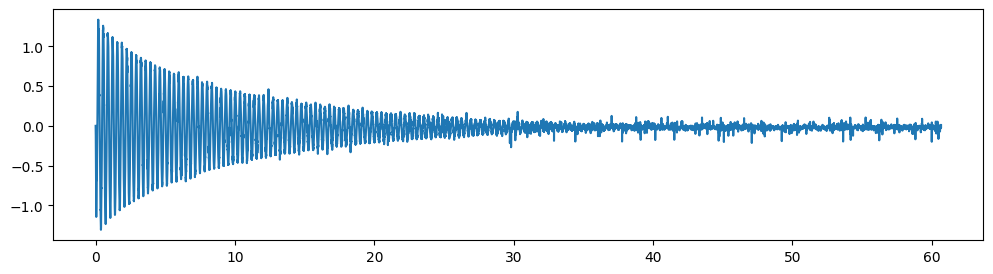

In [65]:
#for i in range(0,len(P2FRF_data)):
    #print(i, ":", P2FRF_data[i])

P2FRF_new_data = P2FRF_data[952:60952]

P2_new_initial_time = P2FRF_new_data[0][0]
for j in range(0, len(P2FRF_new_data)):
    P2FRF_new_data[j][0] -= P2_new_initial_time
    P2FRF_new_data[j][0] = round(P2FRF_new_data[j][0],5)


plt.plot(extract_table(P2FRF_new_data, 0), extract_table(P2FRF_new_data, 1), label = "P1 30cm")

P2FRF_new_data = np.array(extract_table(P2FRF_new_data, 1))

print(P2FRF_new_data.shape)

(60000,)


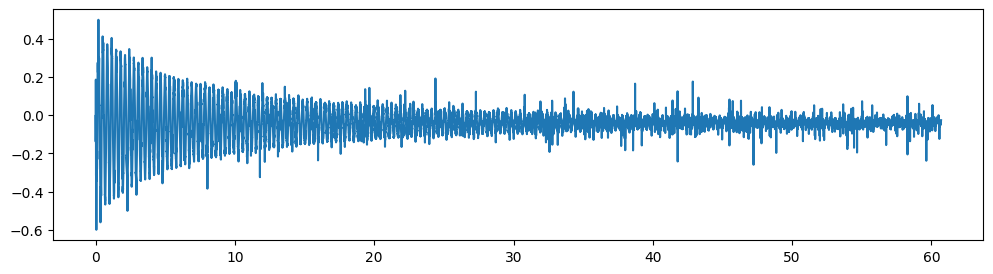

In [64]:

P3FRF_new_data = P3FRF_data[1052:61052]

P3_new_initial_time = P3FRF_new_data[0][0]
for j in range(0, len(P3FRF_new_data)):
    P3FRF_new_data[j][0] -= P3_new_initial_time
    P3FRF_new_data[j][0] = round(P3FRF_new_data[j][0],5)


plt.plot(extract_table(P3FRF_new_data, 0), extract_table(P3FRF_new_data, 1), label = "P1 30cm")

P3FRF_new_data = np.array(extract_table(P3FRF_new_data, 1))

print(P3FRF_new_data.shape)

/tmp/ipykernel_6414/4255176855.py:1: RuntimeWarning: divide by zero encountered in divide
  plt.plot(tt, 1/P3FRF_new_data)


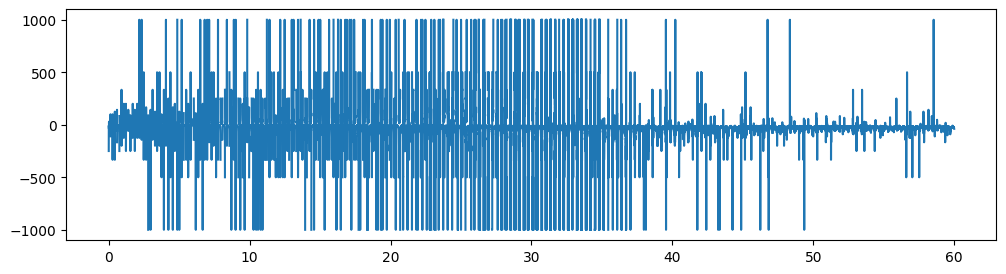

In [115]:
plt.plot(tt, 1/P3FRF_new_data)

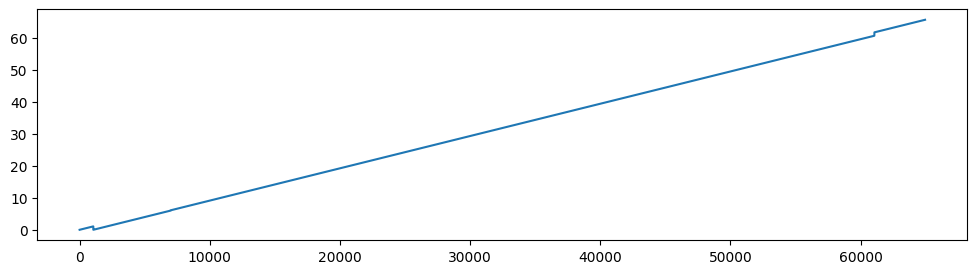

In [94]:
plt.plot(extract_table(P3FRF_data, 0))

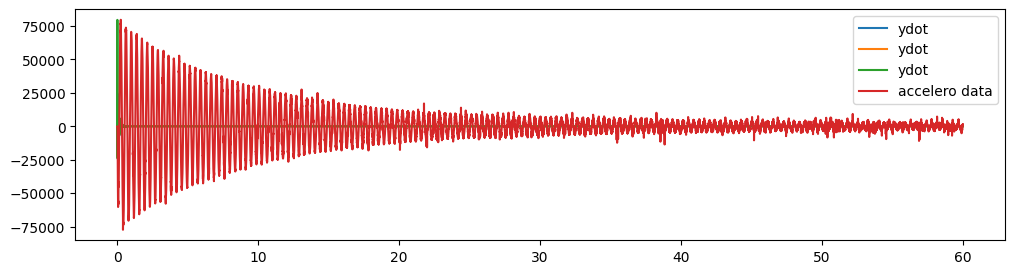

In [91]:
## Comparaison ydot accel et nos données
plt.plot(tt[:],ydot[:,1:11:4], label = "ydot");
plt.plot(tt[:], P1FRF_new_data*40000, label = "accelero data")
plt.legend()

## Calcul des 3 FRFs (avec vérification)

SXY11 [0.         0.01878005 0.01878005 ... 0.01878005 0.01878005 0.00939002]
H[ ] [        nan       +nanj  0.03220556-0.05462197j  0.02013341-0.04246195j
 ... -0.00086433-0.00043256j -0.00177659-0.00013134j
 -0.00079   +0.j        ] (4097,)
H[ ] [            nan           +nanj -1.70268868e-02-2.98925264e-02j
 -2.21699538e-02-2.34399845e-02j ... -5.71654250e-05-5.30454808e-05j
  3.01308820e-05-7.87393738e-04j  1.53000000e-04+0.00000000e+00j] (4097,)
H[ ] [        nan           +nanj -0.00326513+5.09714243e-03j
 -0.01044513-3.60732799e-03j ...  0.00105587+7.21159484e-05j
  0.00040943-1.00073065e-03j -0.000142  +0.00000000e+00j] (4097,)


/tmp/ipykernel_6414/453011344.py:19: RuntimeWarning: invalid value encountered in divide
  H11=Sxy11/Sxx11;
/tmp/ipykernel_6414/453011344.py:25: RuntimeWarning: invalid value encountered in divide
  H12=Sxy12/Sxx12;
/tmp/ipykernel_6414/453011344.py:31: RuntimeWarning: invalid value encountered in divide
  H13=Sxy13/Sxx13;
/tmp/ipykernel_6414/453011344.py:62: RuntimeWarning: divide by zero encountered in log10
  plt.plot(f,20*np.log10(np.abs(inrt[i])),':');


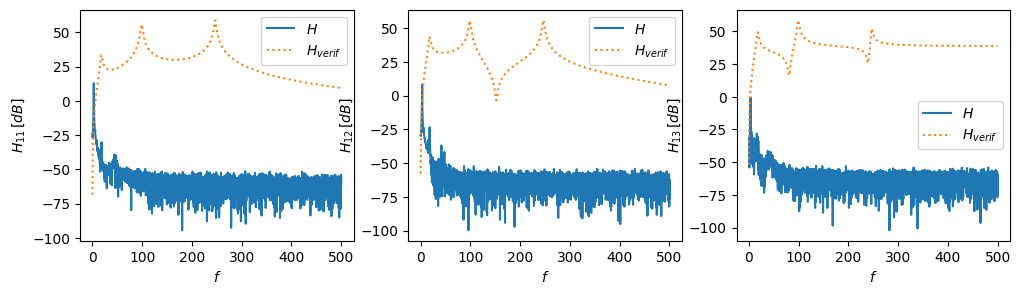

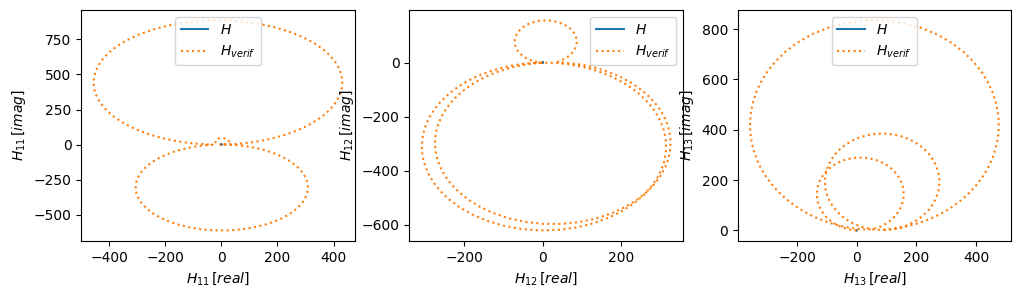

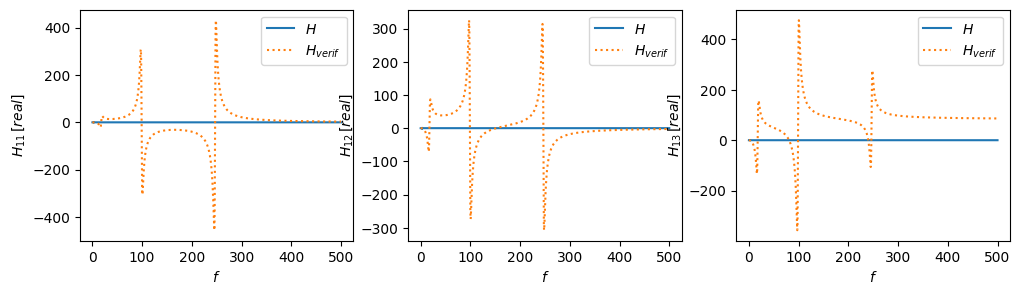

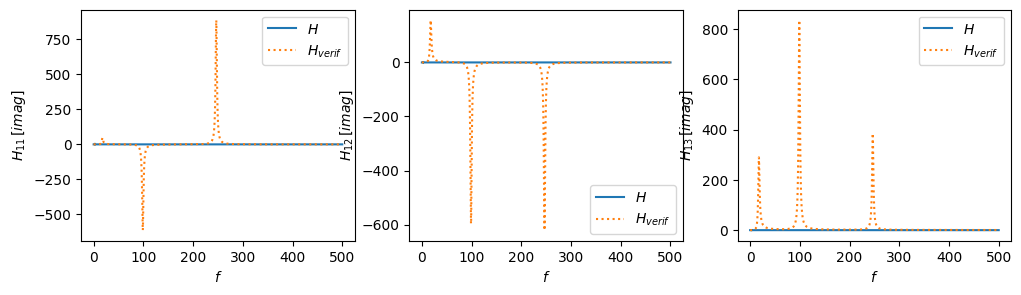

In [133]:
# Calcul des 3 FRFs à partir des signaux temporels
H=[];
NN=len(tt);
data_fe = 1000 #hz

ff[0] = 1000
ff[1] = 0
###########################
'''
for i in range (0,3):
    f,Sxy=signal.csd(ff,ydot[:,(1+4*i)],(NN-1)/NN/hh,window='boxcar',nperseg=8192);
    f,Sxx=signal.csd(ff,ff,(NN-1)/NN/hh,window='boxcar',nperseg=8192);
    H.append(Sxy/Sxx);
'''
#
f,Sxy11=signal.csd(ff,P1FRF_new_data,data_fe,window='boxcar', nperseg=8192);
f,Sxx11=signal.csd(ff,ff,data_fe,window='boxcar',nperseg=8192);
print("SXY11",Sxx11)
H11=Sxy11/Sxx11;
print("H[","]", H11, (H11).shape)
H.append(H11)
#
f,Sxy12=signal.csd(ff,P2FRF_new_data,data_fe,window='boxcar',nperseg=8192);
f,Sxx12=signal.csd(ff,ff,data_fe,window='boxcar',nperseg=8192);
H12=Sxy12/Sxx12;
print("H[","]", H12, (H12).shape)
H.append(H12)
#
f,Sxy13=signal.csd(ff,P3FRF_new_data,data_fe,window='boxcar',nperseg=8192);
f,Sxx13=signal.csd(ff,ff,data_fe,window='boxcar',nperseg=8192);
H13=Sxy13/Sxx13;
print("H[","]", H13, (H13).shape)
H.append(H13)

###########################

# Calcul de vérification (à partir des matrices M, B et K)
inrt1=np.zeros(f.shape, dtype=complex);
inrt2=np.zeros(f.shape, dtype=complex);
inrt3=np.zeros(f.shape, dtype=complex);

for i in range(len(f)):
    #print("i =",i);
    mbk=kk+1j*2*np.pi*f[i]*bb-((2*np.pi*f[i])**2)*mm;
    mbki=np.linalg.inv(mbk);  
    inrt1[i]=mbki[4,0];
    inrt2[i]=mbki[4,2];
    inrt3[i]=mbki[4,4];
    
inrt1=-inrt1*(2*np.pi*f)**2; # passage de l'inertance à l'admittance
inrt2=-inrt2*(2*np.pi*f)**2;
inrt3=-inrt3*(2*np.pi*f)**2;
inrt=[inrt1,inrt2,inrt3];


# affichage de l'amplitude

plt.figure();
for i in range(0,3):
    plt.subplot(1,3,i+1);
    plt.plot(f,20*np.log10(np.abs(H[i])));
    plt.plot(f,20*np.log10(np.abs(inrt[i])),':');
    plt.xlabel("$f$");
    plt.ylabel("$H_{1"+str((i+1))+"} \, [dB]$");
    plt.legend(['$H$','$H_{verif}$'])
    
# affichage des cercles de Nyquist
plt.figure();
for i in range (0,3):
    plt.subplot(1,3,i+1);
    plt.plot(np.real(H[i]),np.imag(H[i]));
    plt.plot(np.real(inrt[i]),np.imag(inrt[i]),':');
    plt.xlabel("$H_{1"+str(i+1)+"} \, [real]$");
    plt.ylabel("$H_{1"+str(i+1)+"} \, [imag]$");
    plt.legend(['$H$','$H_{verif}$'])
    
# affichage partie réelle
plt.figure();
for i in range(0,3):
    plt.subplot(1,3,i+1);
    plt.plot(f,np.real(H[i]));
    plt.plot(f,np.real(inrt[i]),':');
    plt.xlabel("$f$");
    plt.ylabel("$H_{1"+str(i+1)+"} \, [real]$");
    plt.legend(['$H$','$H_{verif}$'])

# affichage de la partie imaginaire
plt.figure();
for i in range(0,3):
    plt.subplot(1,3,i+1);
    plt.plot(f,np.imag(H[i]));
    plt.plot(f,np.imag(inrt[i]),':');
    plt.xlabel("$f$");
    plt.ylabel("$H_{1"+str(i+1)+"} \, [imag]$");
    plt.legend(['$H$','$H_{verif}$'])
 

# Peak picking

### 1- Identifier les pics des différents modes $k$ sur le tracé de la FRF, ainsi que leur amplitude $\vert \alpha_{k} \vert_{max}$.
### 2- Calculer les bandes passantes à -3dB ($\vert \alpha_{k} \vert_{max}/\sqrt{2}$) et les pulsations associées $\omega_{k,a}$ et $\omega_{k,b}$, pour chacun des pics.
### 3- Calculer les taux d'amortissement modaux :
\begin{equation}
b_{k}=\frac{1}{2}\frac{\omega_{k,a}^{2}-\omega_{k,b}^{2}}{\omega_{k}^{2}} \approx \frac{1}{2} \frac{\omega_{k,a}-\omega_{k,b}}{\omega_{k}}
\end{equation}

## FRF 1

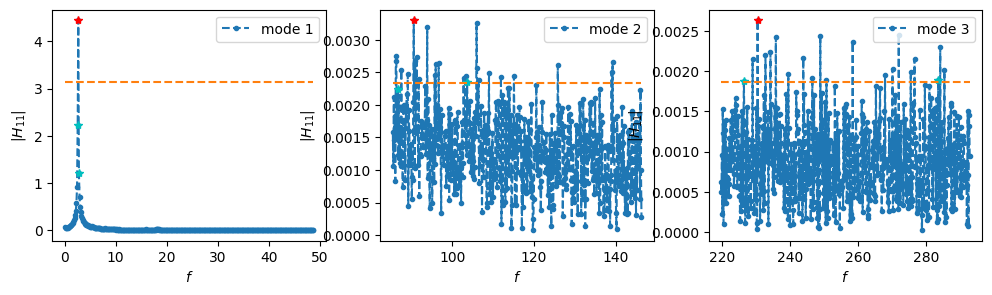

In [134]:
ipeak_H11_m1=range(0,400);
ipeak_H11_m2=range(700,1200);
ipeak_H11_m3=range(1800,2400);
ipeak_H11_m=[ipeak_H11_m1,ipeak_H11_m2,ipeak_H11_m3];

plt.figure();
for i in range(0,3):
    plt.subplot(1,3,(i+1));
    plt.plot(f[ipeak_H11_m[i]],np.abs(H[0][ipeak_H11_m[i]]),'.--');
    plt.ylabel("$|H_{11}|$");
    plt.legend(["mode "+str(i+1)]);

    

#cette fonction calcule le Hmax et la bande 3db pour les 3 mods
def mod(H,ipeak,j):
    for i in ipeak:
        if np.abs(H[i])>Hmax_H11_m[j]:
            imax_H11_m[j]=i;
            Hmax_H11_m[j]=np.abs(H[i]);

    i3dB_H11_m.append(0);i3dB_H11_mbis.append(0);H3dB_H11_m.append(1000);H3dB_H11_mbis.append(1000);
    for i in ipeak:
        if (np.abs((np.abs(H[i])-np.abs(H[imax_H11_m[j]])/np.sqrt(2)))<H3dB_H11_m[j])and(i<imax_H11_m[j]):
            i3dB_H11_m[j]=i;
            H3dB_H11_m[j]=np.abs(np.abs(H[i])-np.abs(H[imax_H11_m[j]])/np.sqrt(2));
        elif (np.abs((np.abs(H[i])-np.abs(H[imax_H11_m[j]])/np.sqrt(2)))<H3dB_H11_mbis[j])and(i>imax_H11_m[j]):
            i3dB_H11_mbis[j]=i;
            H3dB_H11_mbis[j]=np.abs(np.abs(H[i])-np.abs(H[imax_H11_m[j]])/np.sqrt(2));

#on les affiche
def aff(H,ipeak,j):
    plt.subplot(1,3,j+1);
    plt.plot(f[imax_H11_m[j]],np.abs(H[imax_H11_m[j]]),'r*');
    plt.plot(f[i3dB_H11_m[j]],np.abs(H[i3dB_H11_m[j]]),'c*');
    plt.plot(f[i3dB_H11_mbis[j]],np.abs(H[i3dB_H11_mbis[j]]),'c*');
    plt.plot(f[ipeak],np.abs(H[imax_H11_m[j]])/np.sqrt(2)*np.ones(len(ipeak)),'--');
    plt.xlabel("$f$");
    plt.ylabel("$|H_{11}|$");

             
            
imax_H11_m=[];Hmax_H11_m=[];
i3dB_H11_m=[];i3dB_H11_mbis=[];
H3dB_H11_m=[];H3dB_H11_mbis=[];
#j=mode
for j in range(0,3):
    imax_H11_m.append(0);Hmax_H11_m.append(-1000);
    mod(H[0],ipeak_H11_m[j],j);
    aff(H[0],ipeak_H11_m[j],j);

imax_H11=[imax_H11_m[0],imax_H11_m[1],imax_H11_m[2]];
i3dB_H11=[i3dB_H11_m[0],i3dB_H11_m[1],i3dB_H11_m[2]];
i3dB_H11bis=[i3dB_H11_mbis[0],i3dB_H11_mbis[1],i3dB_H11_mbis[2]];

br_pp_H11=(f[i3dB_H11bis]-f[i3dB_H11])/f[imax_H11]/2;

imax=[]
br_pp=[]
imax.append(imax_H11)
br_pp.append(br_pp_H11)

## FRF 2

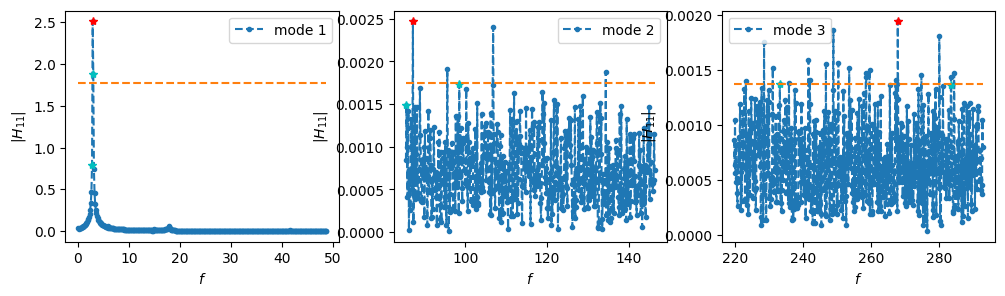

In [81]:
ipeak_H12_m1=range(0,400);
ipeak_H12_m2=range(700,1200);
ipeak_H12_m3=range(1800,2400);
ipeak_H12_m=[ipeak_H12_m1,ipeak_H12_m2,ipeak_H12_m3];
plt.figure();
for i in range(0,3):
    plt.subplot(1,3,(i+1));
    plt.plot(f[ipeak_H12_m[i]],np.abs(H[1][ipeak_H12_m[i]]),'.--');
    plt.ylabel("$|H_{12}|$");
    plt.legend(["mode "+str(i+1)]);

imax_H11_m=[];Hmax_H11_m=[];
i3dB_H11_m=[];i3dB_H11_mbis=[];
H3dB_H11_m=[];H3dB_H11_mbis=[];
#j=mode
for j in range(0,3):
    imax_H11_m.append(0);Hmax_H11_m.append(-1000);
    mod(H[1],ipeak_H12_m[j],j);
    aff(H[1],ipeak_H12_m[j],j);
    
    

imax_H12=[imax_H11_m[0],imax_H11_m[1],imax_H11_m[2]];
i3dB_H12=[i3dB_H11_m[0],i3dB_H11_m[1],i3dB_H11_m[2]];
i3dB_H12bis=[i3dB_H11_mbis[0],i3dB_H11_mbis[1],i3dB_H11_mbis[2]];


br_pp_H12=(f[i3dB_H11bis]-f[i3dB_H11])/f[imax_H11]/2;

imax.append(imax_H12)
br_pp.append(br_pp_H12)

## FRF 3

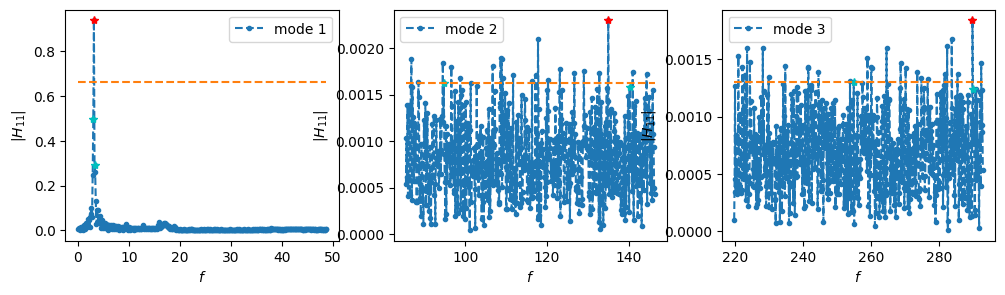

In [82]:
ipeak_H13_m1=range(0,400);
ipeak_H13_m2=range(700,1200);
ipeak_H13_m3=range(1800,2400);
ipeak_H13_m=[ipeak_H13_m1,ipeak_H13_m2,ipeak_H13_m3];
plt.figure();
for i in range(0,3):
    plt.subplot(1,3,(i+1));
    plt.plot(f[ipeak_H13_m[i]],np.abs(H[2][ipeak_H13_m[i]]),'.--');
    plt.ylabel("$|H_{13}|$");
    plt.legend(["mode "+str(i+1)]);   

imax_H11_m=[];Hmax_H11_m=[];
i3dB_H11_m=[];i3dB_H11_mbis=[];
H3dB_H11_m=[];H3dB_H11_mbis=[];
#j=mode
for j in range(0,3):
    imax_H11_m.append(0);Hmax_H11_m.append(-1000);
    mod(H[2],ipeak_H13_m[j],j);
    aff(H[2],ipeak_H13_m[j],j);

imax_H13=[imax_H11_m[0],imax_H11_m[1],imax_H11_m[2]];
i3dB_H13=[i3dB_H11_m[0],i3dB_H11_m[1],i3dB_H11_m[2]];
i3dB_H13bis=[i3dB_H11_mbis[0],i3dB_H11_mbis[1],i3dB_H11_mbis[2]];


br_pp_H13=(f[i3dB_H13bis]-f[i3dB_H13])/f[imax_H13]/2;

imax.append(imax_H13)
br_pp.append(br_pp_H13)

### 4- Déterminer les modes propres.

Pour chaque FRF $p$ et pour chaque mode $k$, on calcule les composantes de la matrice $\left[ A \right]$ donnée par :
\begin{equation}
A_{k,p}=\vert \alpha_{k,p} \vert_{max} \omega_{k}^{2} b_{k}
\end{equation}

On en déduit les modes :
\begin{equation}
\Phi_{k}=\frac{\lbrace A_{k} \rbrace}{\lbrace A_{k} \rbrace}_{j}
\end{equation}

Où "j" correspond au "driving point". Il reste à normer les modes pour comparaison.

\begin{equation}
\Phi_{k}^{norm}=\frac{\lbrace \Phi_{k} \rbrace}{\sum_{i=1}^{N} \lbrace \Phi_{k} \rbrace_{i}^{2}}
\end{equation}

f[imax_H11] [ 20.0175293  111.31699219 277.43807373] | br_pp_H11 [0.08536585 0.01425439 0.00571931]
f[imax_H12] [ 20.0175293  111.19493408 277.43807373] | br_pp_H12 [0.08536585 0.01425439 0.00571931]
f[imax_H13] [ 20.0175293  111.43905029 277.80424805] | br_pp_H13 [0.08231707 0.01478642 0.00659051]


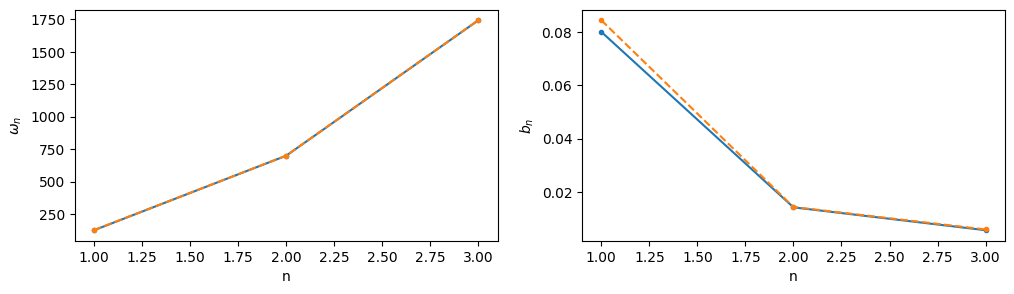

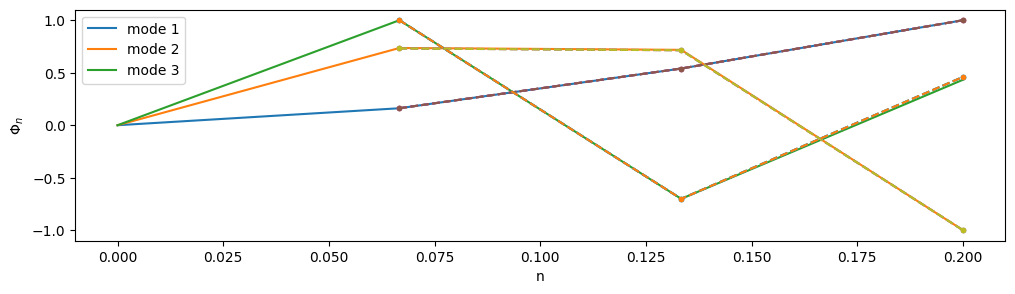

In [13]:
# moyennage des résultats obtenus par 3 FRFs
for i in range(0,3):
    print("f[imax_H1"+str(i+1)+"]",f[imax[i]],"| br_pp_H1"+str(i+1),br_pp[i]);
omega_pp=2*np.pi*(f[imax[0]]+f[imax[1]]+f[imax[2]])/3;
moy_br_pp=(br_pp[0]+br_pp[1]+br_pp[2])/3;

# Construction de la matrice modale
def MaMo(H,imax):
    A_m_pp=[]
    for i in range(0,3):
        var=np.sign(np.imag(H[imax[i]]))*np.abs(H[imax[i]])*br_pp[i]*(omega_pp[i])**2
        A_m_pp.append(var);
    return A_m_pp

A1=MaMo(H[0],imax_H11)   
A2=MaMo(H[1],imax_H12)
A3=MaMo(H[2],imax_H13)

A_m1_pp=[A1[0],A2[0],A3[0]]/A1[0];
A_m1_pp=A_m1_pp/np.max(np.abs(A_m1_pp));
A_m2_pp=[A1[1],A2[1],A3[1]]/A1[1];
A_m2_pp=A_m2_pp/np.max(np.abs(A_m2_pp));
A_m3_pp=[A1[2],A2[2],A3[2]]/A1[2];
A_m3_pp=A_m3_pp/np.max(np.abs(A_m3_pp));

plt.figure();
plt.subplot(1,2,1);
plt.plot(range(1,4),omegar_[0:3],'.-');
plt.plot(range(1,4),omega_pp,'.--');
plt.xlabel("n");
plt.ylabel("$\omega_{n}$");

plt.subplot(1,2,2);
plt.plot(range(1,4),br_[0:3],'.-');
plt.plot(range(1,4),moy_br_pp,'.--');
plt.xlabel("n");
plt.ylabel("$b_{n}$");

plt.figure();
for i in range(3):
    plt.plot(np.arange(0,n_elem+1,1)/(n_elem)*l,vps[0:2*n_elem+1:2,i]/np.max(np.abs(vps[0:2*n_elem+1:2,i]))*np.sign(vps[2,i]),'-');
plt.plot(np.arange(1,n_elem+1,1)/(n_elem)*l,np.sign(A_m1_pp[0])*A_m1_pp,'.--');
plt.plot(np.arange(1,n_elem+1,1)/(n_elem)*l,np.sign(A_m1_pp[0])*A_m2_pp,'.--');
plt.plot(np.arange(1,n_elem+1,1)/(n_elem)*l,np.sign(A_m1_pp[0])*A_m3_pp,'.--');
plt.xlabel("n");
plt.ylabel("$\Phi_{n}$");
plt.legend(["mode 1","mode 2","mode 3"]);

### Modal Scale Factor

\begin{equation}
MSF(t,e)=\frac{\sum_{j=1}^{n} \Phi_{t,j} \Phi_{e,j}^{*}}{\sum_{j=1}^{n} \Phi_{e,j} \Phi_{e,j}^{*}}
\end{equation}

### Modal Assurance Criterion

\begin{equation}
MAC(t,e)=\frac{\vert \sum_{j=1}^{n} \Phi_{t,j} \Phi_{e,j}^{*} \vert^{2}}{\sum_{j=1}^{n} \Phi_{e,j} \Phi_{e,j}^{*} \sum_{j=1}^{n} \Phi_{t,j} \Phi_{t,j}^{*}}
\end{equation}

In [14]:
phi=[]
phipp=[]
for i in range (0,3):
    phi.append(vps[2:2*n_elem+1:2,i]/np.max(np.abs(vps[2:2*n_elem+1:2,i]))*np.sign(vps[2,i]))
    phipp.append(np.sign(A_m1_pp[0])*A_m1_pp)
'''
Phi1_t=vps[2:2*n_elem+1:2,0]/np.max(np.abs(vps[2:2*n_elem+1:2,0]))*np.sign(vps[2,0]);
Phi2_t=vps[2:2*n_elem+1:2,1]/np.max(np.abs(vps[2:2*n_elem+1:2,1]))*np.sign(vps[2,1]);
Phi3_t=vps[2:2*n_elem+1:2,2]/np.max(np.abs(vps[2:2*n_elem+1:2,2]))*np.sign(vps[2,2]);
Phi1pp_e=np.sign(A_m1_pp[0])*A_m1_pp;
Phi2pp_e=np.sign(A_m2_pp[0])*A_m2_pp;
Phi3pp_e=np.sign(A_m3_pp[0])*A_m3_pp;
'''
print(Phi1_t)
print(Phi1pp_e)

print("Phi1_t=",Phi1_t);
print("Phi2_t=",Phi2_t);
print("Phi3_t=",Phi3_t);
print("****************");
print("Phi1pp_e=",Phi1pp_e);
print("Phi2pp_e=",Phi2pp_e);
print("Phi3pp_e=",Phi3pp_e);
print("****************");

MSF_pp=np.zeros((3,3));
MSF_pp[0,0]=np.vdot(Phi1_t,Phi1pp_e)/np.vdot(Phi1pp_e,Phi1pp_e);
MSF_pp[0,1]=np.vdot(Phi1_t,Phi2pp_e)/np.vdot(Phi2pp_e,Phi2pp_e);
MSF_pp[0,2]=np.vdot(Phi1_t,Phi3pp_e)/np.vdot(Phi3pp_e,Phi3pp_e);
MSF_pp[1,0]=np.vdot(Phi2_t,Phi1pp_e)/np.vdot(Phi1pp_e,Phi1pp_e);
MSF_pp[1,1]=np.vdot(Phi2_t,Phi2pp_e)/np.vdot(Phi2pp_e,Phi2pp_e);
MSF_pp[1,2]=np.vdot(Phi2_t,Phi3pp_e)/np.vdot(Phi3pp_e,Phi3pp_e);
MSF_pp[2,0]=np.vdot(Phi3_t,Phi1pp_e)/np.vdot(Phi1pp_e,Phi1pp_e);
MSF_pp[2,1]=np.vdot(Phi3_t,Phi2pp_e)/np.vdot(Phi2pp_e,Phi2pp_e);
MSF_pp[2,2]=np.vdot(Phi3_t,Phi3pp_e)/np.vdot(Phi3pp_e,Phi3pp_e);
print("MSF_pp=",MSF_pp);

MAC_pp=np.zeros((3,3));
MAC_pp[0,0]=np.vdot(Phi1_t,Phi1pp_e)**2/np.vdot(Phi1pp_e,Phi1pp_e)/np.vdot(Phi1_t,Phi1_t);
MAC_pp[0,1]=np.vdot(Phi1_t,Phi2pp_e)**2/np.vdot(Phi2pp_e,Phi2pp_e)/np.vdot(Phi1_t,Phi1_t);
MAC_pp[0,2]=np.vdot(Phi1_t,Phi3pp_e)**2/np.vdot(Phi3pp_e,Phi3pp_e)/np.vdot(Phi1_t,Phi1_t);
MAC_pp[1,0]=np.vdot(Phi2_t,Phi1pp_e)**2/np.vdot(Phi1pp_e,Phi1pp_e)/np.vdot(Phi2_t,Phi2_t);
MAC_pp[1,1]=np.vdot(Phi2_t,Phi2pp_e)**2/np.vdot(Phi2pp_e,Phi2pp_e)/np.vdot(Phi2_t,Phi2_t);
MAC_pp[1,2]=np.vdot(Phi2_t,Phi3pp_e)**2/np.vdot(Phi3pp_e,Phi3pp_e)/np.vdot(Phi2_t,Phi2_t);
MAC_pp[2,0]=np.vdot(Phi3_t,Phi1pp_e)**2/np.vdot(Phi1pp_e,Phi1pp_e)/np.vdot(Phi3_t,Phi3_t);
MAC_pp[2,1]=np.vdot(Phi3_t,Phi2pp_e)**2/np.vdot(Phi2pp_e,Phi2pp_e)/np.vdot(Phi3_t,Phi3_t);
MAC_pp[2,2]=np.vdot(Phi3_t,Phi3pp_e)**2/np.vdot(Phi3pp_e,Phi3pp_e)/np.vdot(Phi3_t,Phi3_t);
print("MAC_pp=",MAC_pp);

NameError: name 'Phi1_t' is not defined

# Circle fitting

### Fonction d'identification de cercles

In [ ]:
x1 = np.r_[36, 36, 19, 18, 33, 26];
y1 = np.r_[14, 10, 28, 31, 18, 26];

def circle_fit(x,y):
    x_m = np.mean(x);
    y_m = np.mean(y);

    def countcalls(fn):
        @functools.wraps(fn)
        def wrapped(*args):
            wrapped.ncalls +=1
            return fn(*args)
        wrapped.ncalls = 0
        return wrapped

    def calc_R(xc,yc):
        return np.sqrt((x-xc)**2+(y-yc)**2)

    @countcalls
    def f_2(c):
        Ri=calc_R(*c)
        return Ri-Ri.mean()

    center_estimate=x_m,y_m;
    center_2,_=optimize.leastsq(f_2,center_estimate);
    xc_2,yc_2=center_2;
    Ri_2=calc_R(xc_2,yc_2);
    R_2=Ri_2.mean();
    residu_2=sum((Ri_2 - R_2)**2);
    residu2_2=sum((Ri_2**2-R_2**2)**2);
    ncalls_2=f_2.ncalls;

    def plot_all(residu2=False):
        plt.axis('equal');
        theta_fit=np.linspace(-np.pi,np.pi,180);
        x_fit2=xc_2+R_2*np.cos(theta_fit);
        y_fit2=yc_2+R_2*np.sin(theta_fit);
        plt.plot(x_fit2,y_fit2,'k--');
        plt.plot([xc_2],[yc_2],'ro');
        #plt.plot(x,y,'ro');
    
    plot_all(residu2=True )
    return xc_2,yc_2,R_2

xc1,yc1,R1=circle_fit(x1,y1); # décommenter pour l'exemple
print("xc1",xc1,"yc1",yc1,"R1",R1);
plt.plot([x1],[y1],'go');

### 1- Identifier les cercles de Nyquist et les pulsations propres

## FRF 1 : lissage des cercles

In [ ]:
ipeak_H11_m1_cf=range(155,175);
ipeak_H11_m2_cf=range(905,925);
ipeak_H11_m3_cf=range(2265,2280);

imax_iH11_m1_cf=0;max_iH11_m1_cf=-1000;
for i in ipeak_H11_m1_cf:
    if np.abs(np.imag(H11[i]))>max_iH11_m1_cf:
        imax_iH11_m1_cf=i;
        max_iH11_m1_cf=np.abs(np.imag(H11[i]));

imax_iH11_m2_cf=0;max_iH11_m2_cf=-1000;
for i in ipeak_H11_m2_cf:
    if np.abs(np.imag(H11[i]))>max_iH11_m2_cf:
        imax_iH11_m2_cf=i;
        max_iH11_m2_cf=np.abs(np.imag(H11[i]));

imax_iH11_m3_cf=0;max_iH11_m3_cf=-1000;
for i in ipeak_H11_m3_cf:
    if np.abs(np.imag(H11[i]))>max_iH11_m3_cf:
        imax_iH11_m3_cf=i;
        max_iH11_m3_cf=np.abs(np.imag(H11[i]));

plt.figure();
plt.subplot(1,3,1);
plt.plot(np.real(H11[0:500]),np.imag(H11[0:500]),'.-');
plt.plot(np.real(H11[ipeak_H11_m1_cf]),np.imag(H11[ipeak_H11_m1_cf]),'.--');
plt.plot(np.real(H11[imax_iH11_m1_cf]),np.imag(H11[imax_iH11_m1_cf]),'bo');
plt.xlabel("$H_{11} \, [real]$");
plt.ylabel("$H_{11} \, [imag]$");
plt.axis('equal');
xc_H11_m1_cf,yc_H11_m1_cf,R_H11_m1_cf=circle_fit(np.real(H11[ipeak_H11_m1_cf]),np.imag(H11[ipeak_H11_m1_cf]));
print("xc_H11_m1_cf",xc_H11_m1_cf,"yc_H11_m1_cf",yc_H11_m1_cf,"R_H11_m1_cf",R_H11_m1_cf);
plt.subplot(1,3,2);
plt.plot(np.real(H11),np.imag(H11),'.-');
plt.plot(np.real(H11[ipeak_H11_m2_cf]),np.imag(H11[ipeak_H11_m2_cf]),'.--');
plt.plot(np.real(H11[imax_iH11_m2_cf]),np.imag(H11[imax_iH11_m2_cf]),'bo');
plt.xlabel("$H_{11} \, [real]$");
plt.ylabel("$H_{11} \, [imag]$");
plt.axis('equal');
xc_H11_m2_cf,yc_H11_m2_cf,R_H11_m2_cf=circle_fit(np.real(H11[ipeak_H11_m2_cf]),np.imag(H11[ipeak_H11_m2_cf]));
print("xc_H11_m2_cf",xc_H11_m2_cf,"yc_H11_m2_cf",yc_H11_m2_cf,"R_H11_m2_cf",R_H11_m2_cf);
plt.subplot(1,3,3);
plt.plot(np.real(H11),np.imag(H11),'.-');
plt.plot(np.real(H11[ipeak_H11_m3_cf]),np.imag(H11[ipeak_H11_m3_cf]),'.--');
plt.plot(np.real(H11[imax_iH11_m3_cf]),np.imag(H11[imax_iH11_m3_cf]),'bo');
plt.xlabel("$H_{11} \, [real]$");
plt.ylabel("$H_{11} \, [imag]$");
plt.axis('equal')
xc_H11_m3_cf,yc_H11_m3_cf,R_H11_m3_cf=circle_fit(np.real(H11[ipeak_H11_m3_cf]),np.imag(H11[ipeak_H11_m3_cf]));
print("xc_H11_m3_cf",xc_H11_m3_cf,"yc_H11_m3_cf",yc_H11_m3_cf,"R_H11_m3_cf",R_H11_m3_cf);

### 2- Calculer les taux d'amortissement modaux
\begin{equation}
b_{r}=\frac{2 \left( \omega_{a}^{2}-\omega_{b}^{2} \right)}{\omega_{r}^{2} \left( tan(\theta_{a}/2) + tan(\theta_{b}/2) \right)}
\end{equation}

### Mode 1

In [ ]:
br_H11_m1_cf=np.zeros((imax_iH11_m1_cf-ipeak_H11_m1_cf[0],ipeak_H11_m1_cf[-1]-imax_iH11_m1_cf-1));
omb=np.zeros((imax_iH11_m1_cf-ipeak_H11_m1_cf[0],1));
oma=np.zeros((ipeak_H11_m1_cf[-1]-imax_iH11_m1_cf-1,1));
omr=f[imax_iH11_m1_cf]*2*np.pi;
xr=np.real(H11[imax_iH11_m1_cf]);
yr=np.imag(H11[imax_iH11_m1_cf]);
ii=0;jj=0;
for i in range(ipeak_H11_m1_cf[0],imax_iH11_m1_cf):
    omb[i-ipeak_H11_m1_cf[0]]=f[i]*2*np.pi;
    for j in range(imax_iH11_m1_cf+1,ipeak_H11_m1_cf[-1]):
        oma[j-imax_iH11_m1_cf-1]=f[j]*2*np.pi;
        xa=np.real(H11[j]);
        ya=np.imag(H11[j]);
        xap=(xa+xr)/2;
        yap=(ya+yr)/2;
        xb=np.real(H11[i]);
        yb=np.imag(H11[i]);
        xbp=(xb+xr)/2;
        ybp=(yb+yr)/2;
        ta2=np.sqrt((xr-xap)**2+(yr-yap)**2)/np.sqrt((xc_H11_m1_cf-xap)**2+(yc_H11_m1_cf-yap)**2);
        tb2=np.sqrt((xr-xbp)**2+(yr-ybp)**2)/np.sqrt((xc_H11_m1_cf-xbp)**2+(yc_H11_m1_cf-ybp)**2);
        br_H11_m1_cf[i-ipeak_H11_m1_cf[0],j-imax_iH11_m1_cf-1]=1/2*((oma[j-imax_iH11_m1_cf-1]**2)-(omb[i-ipeak_H11_m1_cf[0]]**2))/(omr**2)/(ta2+tb2);
        jj=jj+1;
    ii=ii+1;

oma,omb=np.meshgrid(oma,omb);

fig = plt.figure()
ax = Axes3D(fig)
surf = ax.plot_surface(oma[1:imax_iH11_m1_cf-ipeak_H11_m1_cf[0]-1,1:ipeak_H11_m1_cf[-1]-imax_iH11_m1_cf-1], omb[1:imax_iH11_m1_cf-ipeak_H11_m1_cf[0]-1,1:ipeak_H11_m1_cf[-1]-imax_iH11_m1_cf-1], br_H11_m1_cf[1:imax_iH11_m1_cf-ipeak_H11_m1_cf[0]-1,1:ipeak_H11_m1_cf[-1]-imax_iH11_m1_cf-1], cmap=cm.coolwarm,linewidth=0, antialiased=False);
ax.set_zlim(-1.01, 1.01);
ax.zaxis.set_major_locator(LinearLocator(10));
ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'));
fig.colorbar(surf, shrink=0.5, aspect=5);
br_H11_m1_cf_mean=np.mean(br_H11_m1_cf[1:imax_iH11_m1_cf-ipeak_H11_m1_cf[0]-1,1:ipeak_H11_m1_cf[-1]-imax_iH11_m1_cf-1]);
print("br_H11_m1_cf_mean =",br_H11_m1_cf_mean);

### Mode 2

In [ ]:
br_H11_m2_cf=np.zeros((imax_iH11_m2_cf-ipeak_H11_m2_cf[0],ipeak_H11_m2_cf[-1]-imax_iH11_m2_cf-1));
omb=np.zeros((imax_iH11_m2_cf-ipeak_H11_m2_cf[0],1));
oma=np.zeros((ipeak_H11_m2_cf[-1]-imax_iH11_m2_cf-1,1));
omr=f[imax_iH11_m2_cf]*2*np.pi;
xr=np.real(H11[imax_iH11_m2_cf]);
yr=np.imag(H11[imax_iH11_m2_cf]);
ii=0;jj=0;
for i in range(ipeak_H11_m2_cf[0],imax_iH11_m2_cf):
    omb[i-ipeak_H11_m2_cf[0]]=f[i]*2*np.pi;
    for j in range(imax_iH11_m2_cf+1,ipeak_H11_m2_cf[-1]):
        oma[j-imax_iH11_m2_cf-1]=f[j]*2*np.pi;
        xa=np.real(H11[j]);
        ya=np.imag(H11[j]);
        xap=(xa+xr)/2;
        yap=(ya+yr)/2;
        xb=np.real(H11[i]);
        yb=np.imag(H11[i]);
        xbp=(xb+xr)/2;
        ybp=(yb+yr)/2;
        ta2=np.sqrt((xr-xap)**2+(yr-yap)**2)/np.sqrt((xc_H11_m2_cf-xap)**2+(yc_H11_m2_cf-yap)**2);
        tb2=np.sqrt((xr-xbp)**2+(yr-ybp)**2)/np.sqrt((xc_H11_m2_cf-xbp)**2+(yc_H11_m2_cf-ybp)**2);
        br_H11_m2_cf[i-ipeak_H11_m2_cf[0],j-imax_iH11_m2_cf-1]=1/2*((oma[j-imax_iH11_m2_cf-1]**2)-(omb[i-ipeak_H11_m2_cf[0]]**2))/(omr**2)/(ta2+tb2);
        jj=jj+1;
    ii=ii+1;

oma,omb=np.meshgrid(oma,omb);

fig = plt.figure();
ax = Axes3D(fig)
surf = ax.plot_surface(oma[1:imax_iH11_m2_cf-ipeak_H11_m2_cf[0]-1,1:ipeak_H11_m2_cf[-1]-imax_iH11_m2_cf-1], omb[1:imax_iH11_m2_cf-ipeak_H11_m2_cf[0]-1,1:ipeak_H11_m2_cf[-1]-imax_iH11_m2_cf-1], br_H11_m2_cf[1:imax_iH11_m2_cf-ipeak_H11_m2_cf[0]-1,1:ipeak_H11_m2_cf[-1]-imax_iH11_m2_cf-1], cmap=cm.coolwarm,linewidth=0, antialiased=False);
ax.set_zlim(-1.01, 1.01);
ax.zaxis.set_major_locator(LinearLocator(10));
ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'));
fig.colorbar(surf, shrink=0.5, aspect=5);
br_H11_m2_cf_mean=np.mean(br_H11_m2_cf[1:imax_iH11_m2_cf-ipeak_H11_m2_cf[0]-1,1:ipeak_H11_m2_cf[-1]-imax_iH11_m2_cf-1]);
print("br_H11_m2_cf_mean =",br_H11_m2_cf_mean);

### Mode 3

In [ ]:
br_H11_m3_cf=np.zeros((imax_iH11_m3_cf-ipeak_H11_m3_cf[0],ipeak_H11_m3_cf[-1]-imax_iH11_m3_cf-1));
omb=np.zeros((imax_iH11_m3_cf-ipeak_H11_m3_cf[0],1));
oma=np.zeros((ipeak_H11_m3_cf[-1]-imax_iH11_m3_cf-1,1));
omr=f[imax_iH11_m3_cf]*2*np.pi;
xr=np.real(H11[imax_iH11_m3_cf]);
yr=np.imag(H11[imax_iH11_m3_cf]);
ii=0;jj=0;
for i in range(ipeak_H11_m3_cf[0],imax_iH11_m3_cf):
    omb[i-ipeak_H11_m3_cf[0]]=f[i]*2*np.pi;
    for j in range(imax_iH11_m3_cf+1,ipeak_H11_m3_cf[-1]):
        oma[j-imax_iH11_m3_cf-1]=f[j]*2*np.pi;
        xa=np.real(H11[j]);
        ya=np.imag(H11[j]);
        xap=(xa+xr)/2;
        yap=(ya+yr)/2;
        xb=np.real(H11[i]);
        yb=np.imag(H11[i]);
        xbp=(xb+xr)/2;
        ybp=(yb+yr)/2;
        ta2=np.sqrt((xr-xap)**2+(yr-yap)**2)/np.sqrt((xc_H11_m3_cf-xap)**2+(yc_H11_m3_cf-yap)**2);
        tb2=np.sqrt((xr-xbp)**2+(yr-ybp)**2)/np.sqrt((xc_H11_m3_cf-xbp)**2+(yc_H11_m3_cf-ybp)**2);
        br_H11_m3_cf[i-ipeak_H11_m3_cf[0],j-imax_iH11_m3_cf-1]=1/2*((oma[j-imax_iH11_m3_cf-1]**2)-(omb[i-ipeak_H11_m3_cf[0]]**2))/(omr**2)/(ta2+tb2);
        jj=jj+1;
    ii=ii+1;

oma,omb=np.meshgrid(oma,omb);

fig = plt.figure();
ax = Axes3D(fig)
surf = ax.plot_surface(oma[1:imax_iH11_m3_cf-ipeak_H11_m3_cf[0]-1,1:ipeak_H11_m3_cf[-1]-imax_iH11_m3_cf-1], omb[1:imax_iH11_m3_cf-ipeak_H11_m3_cf[0]-1,1:ipeak_H11_m3_cf[-1]-imax_iH11_m3_cf-1], br_H11_m3_cf[1:imax_iH11_m3_cf-ipeak_H11_m3_cf[0]-1,1:ipeak_H11_m3_cf[-1]-imax_iH11_m3_cf-1], cmap=cm.coolwarm,linewidth=0, antialiased=False);
ax.set_zlim(-1.01, 1.01);
ax.zaxis.set_major_locator(LinearLocator(10));
ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'));
fig.colorbar(surf, shrink=0.5, aspect=5);
br_H11_m3_cf_mean=np.mean(br_H11_m3_cf[1:imax_iH11_m3_cf-ipeak_H11_m3_cf[0]-1,1:ipeak_H11_m3_cf[-1]-imax_iH11_m3_cf-1]);
print("br_H11_m3_cf_mean =",br_H11_m3_cf_mean);

## FRF 2 : lissage des cercles

In [ ]:
ipeak_H12_m1_cf=range(155,175);
ipeak_H12_m2_cf=range(905,925);
ipeak_H12_m3_cf=range(2265,2280);

imax_iH12_m1_cf=0;max_iH12_m1_cf=-1000;
for i in ipeak_H12_m1_cf:
    if np.abs(np.imag(H12[i]))>max_iH12_m1_cf:
        imax_iH12_m1_cf=i;
        max_iH12_m1_cf=np.abs(np.imag(H12[i]));

imax_iH12_m2_cf=0;max_iH12_m2_cf=-1000;
for i in ipeak_H12_m2_cf:
    if np.abs(np.imag(H12[i]))>max_iH12_m2_cf:
        imax_iH12_m2_cf=i;
        max_iH12_m2_cf=np.abs(np.imag(H12[i]));

imax_iH12_m3_cf=0;max_iH12_m3_cf=-1000;
for i in ipeak_H12_m3_cf:
    if np.abs(np.imag(H12[i]))>max_iH12_m3_cf:
        imax_iH12_m3_cf=i;
        max_iH12_m3_cf=np.abs(np.imag(H12[i]));

plt.figure();
plt.subplot(1,3,1);
plt.plot(np.real(H12),np.imag(H12),'.-');
plt.plot(np.real(H12[ipeak_H12_m1_cf]),np.imag(H12[ipeak_H12_m1_cf]),'.--');
plt.plot(np.real(H12[imax_iH12_m1_cf]),np.imag(H12[imax_iH12_m1_cf]),'bo');
plt.xlabel("$H_{11} \, [real]$");
plt.ylabel("$H_{11} \, [imag]$");
plt.axis('equal');
xc_H12_m1_cf,yc_H12_m1_cf,R_H12_m1_cf=circle_fit(np.real(H12[ipeak_H12_m1_cf]),np.imag(H12[ipeak_H12_m1_cf]));
print("xc_H12_m1_cf",xc_H12_m1_cf,"yc_H12_m1_cf",yc_H12_m1_cf,"R_H12_m1_cf",R_H12_m1_cf);
plt.subplot(1,3,2);
plt.plot(np.real(H12),np.imag(H12),'.-');
plt.plot(np.real(H12[ipeak_H12_m2_cf]),np.imag(H12[ipeak_H12_m2_cf]),'.--');
plt.plot(np.real(H12[imax_iH12_m2_cf]),np.imag(H12[imax_iH12_m2_cf]),'bo');
plt.xlabel("$H_{11} \, [real]$");
plt.ylabel("$H_{11} \, [imag]$");
plt.axis('equal');
xc_H12_m2_cf,yc_H12_m2_cf,R_H12_m2_cf=circle_fit(np.real(H12[ipeak_H12_m2_cf]),np.imag(H12[ipeak_H12_m2_cf]));
print("xc_H12_m2_cf",xc_H12_m2_cf,"yc_H12_m2_cf",yc_H12_m2_cf,"R_H12_m2_cf",R_H12_m2_cf);
plt.subplot(1,3,3);
plt.plot(np.real(H12),np.imag(H12),'.-');
plt.plot(np.real(H12[ipeak_H12_m3_cf]),np.imag(H12[ipeak_H12_m3_cf]),'.--');
plt.plot(np.real(H12[imax_iH12_m3_cf]),np.imag(H12[imax_iH12_m3_cf]),'bo');
plt.xlabel("$H_{11} \, [real]$");
plt.ylabel("$H_{11} \, [imag]$");
plt.axis('equal')
xc_H12_m3_cf,yc_H12_m3_cf,R_H12_m3_cf=circle_fit(np.real(H12[ipeak_H12_m3_cf]),np.imag(H12[ipeak_H12_m3_cf]));
print("xc_H12_m3_cf",xc_H12_m3_cf,"yc_H12_m3_cf",yc_H12_m3_cf,"R_H12_m3_cf",R_H12_m3_cf);

### Mode 1

In [ ]:
br_H12_m1_cf=np.zeros((imax_iH12_m1_cf-ipeak_H12_m1_cf[0],ipeak_H12_m1_cf[-1]-imax_iH12_m1_cf-1));
omb=np.zeros((imax_iH12_m1_cf-ipeak_H12_m1_cf[0],1));
oma=np.zeros((ipeak_H12_m1_cf[-1]-imax_iH12_m1_cf-1,1));
omr=f[imax_iH12_m1_cf]*2*np.pi;
xr=np.real(H12[imax_iH12_m1_cf]);
yr=np.imag(H12[imax_iH12_m1_cf]);
ii=0;jj=0;
for i in range(ipeak_H12_m1_cf[0],imax_iH12_m1_cf):
    omb[i-ipeak_H12_m1_cf[0]]=f[i]*2*np.pi;
    for j in range(imax_iH12_m1_cf+1,ipeak_H12_m1_cf[-1]):
        oma[j-imax_iH12_m1_cf-1]=f[j]*2*np.pi;
        xa=np.real(H12[j]);
        ya=np.imag(H12[j]);
        xap=(xa+xr)/2;
        yap=(ya+yr)/2;
        xb=np.real(H12[i]);
        yb=np.imag(H12[i]);
        xbp=(xb+xr)/2;
        ybp=(yb+yr)/2;
        ta2=np.sqrt((xr-xap)**2+(yr-yap)**2)/np.sqrt((xc_H12_m1_cf-xap)**2+(yc_H12_m1_cf-yap)**2);
        tb2=np.sqrt((xr-xbp)**2+(yr-ybp)**2)/np.sqrt((xc_H12_m1_cf-xbp)**2+(yc_H12_m1_cf-ybp)**2);
        br_H12_m1_cf[i-ipeak_H12_m1_cf[0],j-imax_iH12_m1_cf-1]=1/2*((oma[j-imax_iH12_m1_cf-1]**2)-(omb[i-ipeak_H12_m1_cf[0]]**2))/(omr**2)/(ta2+tb2);
        jj=jj+1;
    ii=ii+1;

oma,omb=np.meshgrid(oma,omb);

fig = plt.figure();
ax = Axes3D(fig)
surf = ax.plot_surface(oma[1:imax_iH12_m1_cf-ipeak_H12_m1_cf[0]-1,1:ipeak_H12_m1_cf[-1]-imax_iH12_m1_cf-1], omb[1:imax_iH12_m1_cf-ipeak_H12_m1_cf[0]-1,1:ipeak_H12_m1_cf[-1]-imax_iH12_m1_cf-1], br_H12_m1_cf[1:imax_iH12_m1_cf-ipeak_H12_m1_cf[0]-1,1:ipeak_H12_m1_cf[-1]-imax_iH12_m1_cf-1], cmap=cm.coolwarm,linewidth=0, antialiased=False);
ax.set_zlim(-1.01, 1.01);
ax.zaxis.set_major_locator(LinearLocator(10));
ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'));
fig.colorbar(surf, shrink=0.5, aspect=5);
br_H12_m1_cf_mean=np.mean(br_H12_m1_cf[1:imax_iH12_m1_cf-ipeak_H12_m1_cf[0]-1,1:ipeak_H12_m1_cf[-1]-imax_iH12_m1_cf-1]);
print("br_H12_m1_cf_mean =",br_H12_m1_cf_mean);

### Mode 2

In [ ]:
br_H12_m2_cf=np.zeros((imax_iH12_m2_cf-ipeak_H12_m2_cf[0],ipeak_H12_m2_cf[-1]-imax_iH12_m2_cf-1));
omb=np.zeros((imax_iH12_m2_cf-ipeak_H12_m2_cf[0],1));
oma=np.zeros((ipeak_H12_m2_cf[-1]-imax_iH12_m2_cf-1,1));
omr=f[imax_iH12_m2_cf]*2*np.pi;
xr=np.real(H12[imax_iH12_m2_cf]);
yr=np.imag(H12[imax_iH12_m2_cf]);
ii=0;jj=0;
for i in range(ipeak_H12_m2_cf[0],imax_iH12_m2_cf):
    omb[i-ipeak_H12_m2_cf[0]]=f[i]*2*np.pi;
    for j in range(imax_iH12_m2_cf+1,ipeak_H12_m2_cf[-1]):
        oma[j-imax_iH12_m2_cf-1]=f[j]*2*np.pi;
        xa=np.real(H12[j]);
        ya=np.imag(H12[j]);
        xap=(xa+xr)/2;
        yap=(ya+yr)/2;
        xb=np.real(H12[i]);
        yb=np.imag(H12[i]);
        xbp=(xb+xr)/2;
        ybp=(yb+yr)/2;
        ta2=np.sqrt((xr-xap)**2+(yr-yap)**2)/np.sqrt((xc_H12_m2_cf-xap)**2+(yc_H12_m2_cf-yap)**2);
        tb2=np.sqrt((xr-xbp)**2+(yr-ybp)**2)/np.sqrt((xc_H12_m2_cf-xbp)**2+(yc_H12_m2_cf-ybp)**2);
        br_H12_m2_cf[i-ipeak_H12_m2_cf[0],j-imax_iH12_m2_cf-1]=1/2*((oma[j-imax_iH12_m2_cf-1]**2)-(omb[i-ipeak_H12_m2_cf[0]]**2))/(omr**2)/(ta2+tb2);
        jj=jj+1;
    ii=ii+1;

oma,omb=np.meshgrid(oma,omb);

fig = plt.figure();
ax = Axes3D(fig)
surf = ax.plot_surface(oma[1:imax_iH12_m2_cf-ipeak_H12_m2_cf[0]-1,1:ipeak_H12_m2_cf[-1]-imax_iH12_m2_cf-1], omb[1:imax_iH12_m2_cf-ipeak_H12_m2_cf[0]-1,1:ipeak_H12_m2_cf[-1]-imax_iH12_m2_cf-1], br_H12_m2_cf[1:imax_iH12_m2_cf-ipeak_H12_m2_cf[0]-1,1:ipeak_H12_m2_cf[-1]-imax_iH12_m2_cf-1], cmap=cm.coolwarm,linewidth=0, antialiased=False);
ax.set_zlim(-1.01, 1.01);
ax.zaxis.set_major_locator(LinearLocator(10));
ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'));
fig.colorbar(surf, shrink=0.5, aspect=5);
br_H12_m2_cf_mean=np.mean(br_H12_m2_cf[1:imax_iH12_m2_cf-ipeak_H12_m2_cf[0]-1,1:ipeak_H12_m2_cf[-1]-imax_iH12_m2_cf-1]);
print("br_H12_m2_cf_mean =",br_H12_m2_cf_mean);

### Mode 3

In [ ]:
br_H12_m3_cf=np.zeros((imax_iH12_m3_cf-ipeak_H12_m3_cf[0],ipeak_H12_m3_cf[-1]-imax_iH12_m3_cf-1));
omb=np.zeros((imax_iH12_m3_cf-ipeak_H12_m3_cf[0],1));
oma=np.zeros((ipeak_H12_m3_cf[-1]-imax_iH12_m3_cf-1,1));
omr=f[imax_iH12_m3_cf]*2*np.pi;
xr=np.real(H12[imax_iH12_m3_cf]);
yr=np.imag(H12[imax_iH12_m3_cf]);
ii=0;jj=0;
for i in range(ipeak_H12_m3_cf[0],imax_iH12_m3_cf):
    omb[i-ipeak_H12_m3_cf[0]]=f[i]*2*np.pi;
    for j in range(imax_iH12_m3_cf+1,ipeak_H12_m3_cf[-1]):
        oma[j-imax_iH12_m3_cf-1]=f[j]*2*np.pi;
        xa=np.real(H12[j]);
        ya=np.imag(H12[j]);
        xap=(xa+xr)/2;
        yap=(ya+yr)/2;
        xb=np.real(H12[i]);
        yb=np.imag(H12[i]);
        xbp=(xb+xr)/2;
        ybp=(yb+yr)/2;
        ta2=np.sqrt((xr-xap)**2+(yr-yap)**2)/np.sqrt((xc_H12_m3_cf-xap)**2+(yc_H12_m3_cf-yap)**2);
        tb2=np.sqrt((xr-xbp)**2+(yr-ybp)**2)/np.sqrt((xc_H12_m3_cf-xbp)**2+(yc_H12_m3_cf-ybp)**2);
        br_H12_m3_cf[i-ipeak_H12_m3_cf[0],j-imax_iH12_m3_cf-1]=1/2*((oma[j-imax_iH12_m3_cf-1]**2)-(omb[i-ipeak_H12_m3_cf[0]]**2))/(omr**2)/(ta2+tb2);
        jj=jj+1;
    ii=ii+1;

oma,omb=np.meshgrid(oma,omb);

fig = plt.figure();
ax = Axes3D(fig)
surf = ax.plot_surface(oma[1:imax_iH12_m3_cf-ipeak_H12_m3_cf[0]-1,1:ipeak_H12_m3_cf[-1]-imax_iH12_m3_cf-1], omb[1:imax_iH12_m3_cf-ipeak_H12_m3_cf[0]-1,1:ipeak_H12_m3_cf[-1]-imax_iH12_m3_cf-1], br_H12_m3_cf[1:imax_iH12_m3_cf-ipeak_H12_m3_cf[0]-1,1:ipeak_H12_m3_cf[-1]-imax_iH12_m3_cf-1], cmap=cm.coolwarm,linewidth=0, antialiased=False);
ax.set_zlim(-1.01, 1.01);
ax.zaxis.set_major_locator(LinearLocator(10));
ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'));
fig.colorbar(surf, shrink=0.5, aspect=5);
br_H12_m3_cf_mean=np.mean(br_H12_m3_cf[1:imax_iH12_m3_cf-ipeak_H12_m3_cf[0]-1,1:ipeak_H12_m3_cf[-1]-imax_iH12_m3_cf-1]);
print("br_H12_m3_cf_mean =",br_H12_m3_cf_mean);

## FRF 3 : lissage des cercles

In [ ]:
ipeak_H13_m1_cf=range(155,175);
ipeak_H13_m2_cf=range(905,925);
ipeak_H13_m3_cf=range(2265,2280);

imax_iH13_m1_cf=0;max_iH13_m1_cf=-1000;
for i in ipeak_H13_m1_cf:
    if np.abs(np.imag(H13[i]))>max_iH13_m1_cf:
        imax_iH13_m1_cf=i;
        max_iH13_m1_cf=np.abs(np.imag(H13[i]));

imax_iH13_m2_cf=0;max_iH13_m2_cf=-1000;
for i in ipeak_H13_m2_cf:
    if np.abs(np.imag(H13[i]))>max_iH13_m2_cf:
        imax_iH13_m2_cf=i;
        max_iH13_m2_cf=np.abs(np.imag(H13[i]));

imax_iH13_m3_cf=0;max_iH13_m3_cf=-1000;
for i in ipeak_H13_m3_cf:
    if np.abs(np.imag(H13[i]))>max_iH13_m3_cf:
        imax_iH13_m3_cf=i;
        max_iH13_m3_cf=np.abs(np.imag(H13[i]));

plt.figure();
plt.subplot(1,3,1);
plt.plot(np.real(H13),np.imag(H13),'.-');
plt.plot(np.real(H13[ipeak_H13_m1_cf]),np.imag(H13[ipeak_H13_m1_cf]),'.--');
plt.plot(np.real(H13[imax_iH13_m1_cf]),np.imag(H13[imax_iH13_m1_cf]),'bo');
plt.xlabel("$H_{11} \, [real]$");
plt.ylabel("$H_{11} \, [imag]$");
plt.axis('equal');
xc_H13_m1_cf,yc_H13_m1_cf,R_H13_m1_cf=circle_fit(np.real(H13[ipeak_H13_m1_cf]),np.imag(H13[ipeak_H13_m1_cf]));
print("xc_H13_m1_cf",xc_H13_m1_cf,"yc_H13_m1_cf",yc_H13_m1_cf,"R_H13_m1_cf",R_H13_m1_cf);
plt.subplot(1,3,2);
plt.plot(np.real(H13),np.imag(H13),'.-');
plt.plot(np.real(H13[ipeak_H13_m2_cf]),np.imag(H13[ipeak_H13_m2_cf]),'.--');
plt.plot(np.real(H13[imax_iH13_m2_cf]),np.imag(H13[imax_iH13_m2_cf]),'bo');
plt.xlabel("$H_{11} \, [real]$");
plt.ylabel("$H_{11} \, [imag]$");
plt.axis('equal');
xc_H13_m2_cf,yc_H13_m2_cf,R_H13_m2_cf=circle_fit(np.real(H13[ipeak_H13_m2_cf]),np.imag(H13[ipeak_H13_m2_cf]));
print("xc_H13_m2_cf",xc_H13_m2_cf,"yc_H13_m2_cf",yc_H13_m2_cf,"R_H13_m2_cf",R_H13_m2_cf);
plt.subplot(1,3,3);
plt.plot(np.real(H13),np.imag(H13),'.-');
plt.plot(np.real(H13[ipeak_H13_m3_cf]),np.imag(H13[ipeak_H13_m3_cf]),'.--');
plt.plot(np.real(H13[imax_iH13_m3_cf]),np.imag(H13[imax_iH13_m3_cf]),'bo');
plt.xlabel("$H_{11} \, [real]$");
plt.ylabel("$H_{11} \, [imag]$");
plt.axis('equal')
xc_H13_m3_cf,yc_H13_m3_cf,R_H13_m3_cf=circle_fit(np.real(H13[ipeak_H13_m3_cf]),np.imag(H13[ipeak_H13_m3_cf]));
print("xc_H13_m3_cf",xc_H13_m3_cf,"yc_H13_m3_cf",yc_H13_m3_cf,"R_H13_m3_cf",R_H13_m3_cf);

### Mode 1

In [ ]:
br_H13_m1_cf=np.zeros((imax_iH13_m1_cf-ipeak_H13_m1_cf[0],ipeak_H13_m1_cf[-1]-imax_iH13_m1_cf-1));
omb=np.zeros((imax_iH13_m1_cf-ipeak_H13_m1_cf[0],1));
oma=np.zeros((ipeak_H13_m1_cf[-1]-imax_iH13_m1_cf-1,1));
omr=f[imax_iH13_m1_cf]*2*np.pi;
xr=np.real(H13[imax_iH13_m1_cf]);
yr=np.imag(H13[imax_iH13_m1_cf]);
ii=0;jj=0;
for i in range(ipeak_H13_m1_cf[0],imax_iH13_m1_cf):
    omb[i-ipeak_H13_m1_cf[0]]=f[i]*2*np.pi;
    for j in range(imax_iH13_m1_cf+1,ipeak_H13_m1_cf[-1]):
        oma[j-imax_iH13_m1_cf-1]=f[j]*2*np.pi;
        xa=np.real(H13[j]);
        ya=np.imag(H13[j]);
        xap=(xa+xr)/2;
        yap=(ya+yr)/2;
        xb=np.real(H13[i]);
        yb=np.imag(H13[i]);
        xbp=(xb+xr)/2;
        ybp=(yb+yr)/2;
        ta2=np.sqrt((xr-xap)**2+(yr-yap)**2)/np.sqrt((xc_H13_m1_cf-xap)**2+(yc_H13_m1_cf-yap)**2);
        tb2=np.sqrt((xr-xbp)**2+(yr-ybp)**2)/np.sqrt((xc_H13_m1_cf-xbp)**2+(yc_H13_m1_cf-ybp)**2);
        br_H13_m1_cf[i-ipeak_H13_m1_cf[0],j-imax_iH13_m1_cf-1]=1/2*((oma[j-imax_iH13_m1_cf-1]**2)-(omb[i-ipeak_H13_m1_cf[0]]**2))/(omr**2)/(ta2+tb2);
        jj=jj+1;
    ii=ii+1;

oma,omb=np.meshgrid(oma,omb);

fig = plt.figure();
ax = Axes3D(fig)
surf = ax.plot_surface(oma[1:imax_iH13_m1_cf-ipeak_H13_m1_cf[0]-1,1:ipeak_H13_m1_cf[-1]-imax_iH13_m1_cf-1], omb[1:imax_iH13_m1_cf-ipeak_H13_m1_cf[0]-1,1:ipeak_H13_m1_cf[-1]-imax_iH13_m1_cf-1], br_H13_m1_cf[1:imax_iH13_m1_cf-ipeak_H13_m1_cf[0]-1,1:ipeak_H13_m1_cf[-1]-imax_iH13_m1_cf-1], cmap=cm.coolwarm,linewidth=0, antialiased=False);
ax.set_zlim(-1.01, 1.01);
ax.zaxis.set_major_locator(LinearLocator(10));
ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'));
fig.colorbar(surf, shrink=0.5, aspect=5);
br_H13_m1_cf_mean=np.mean(br_H13_m1_cf[1:imax_iH13_m1_cf-ipeak_H13_m1_cf[0]-1,1:ipeak_H13_m1_cf[-1]-imax_iH13_m1_cf-1]);
print("br_H13_m1_cf_mean =",br_H13_m1_cf_mean);

### Mode 2

In [ ]:
br_H13_m2_cf=np.zeros((imax_iH13_m2_cf-ipeak_H13_m2_cf[0],ipeak_H13_m2_cf[-1]-imax_iH13_m2_cf-1));
omb=np.zeros((imax_iH13_m2_cf-ipeak_H13_m2_cf[0],1));
oma=np.zeros((ipeak_H13_m2_cf[-1]-imax_iH13_m2_cf-1,1));
omr=f[imax_iH13_m2_cf]*2*np.pi;
xr=np.real(H13[imax_iH13_m2_cf]);
yr=np.imag(H13[imax_iH13_m2_cf]);
ii=0;jj=0;
for i in range(ipeak_H13_m2_cf[0],imax_iH13_m2_cf):
    omb[i-ipeak_H13_m2_cf[0]]=f[i]*2*np.pi;
    for j in range(imax_iH13_m2_cf+1,ipeak_H13_m2_cf[-1]):
        oma[j-imax_iH13_m2_cf-1]=f[j]*2*np.pi;
        xa=np.real(H13[j]);
        ya=np.imag(H13[j]);
        xap=(xa+xr)/2;
        yap=(ya+yr)/2;
        xb=np.real(H13[i]);
        yb=np.imag(H13[i]);
        xbp=(xb+xr)/2;
        ybp=(yb+yr)/2;
        ta2=np.sqrt((xr-xap)**2+(yr-yap)**2)/np.sqrt((xc_H13_m2_cf-xap)**2+(yc_H13_m2_cf-yap)**2);
        tb2=np.sqrt((xr-xbp)**2+(yr-ybp)**2)/np.sqrt((xc_H13_m2_cf-xbp)**2+(yc_H13_m2_cf-ybp)**2);
        br_H13_m2_cf[i-ipeak_H13_m2_cf[0],j-imax_iH13_m2_cf-1]=1/2*((oma[j-imax_iH13_m2_cf-1]**2)-(omb[i-ipeak_H13_m2_cf[0]]**2))/(omr**2)/(ta2+tb2);
        jj=jj+1;
    ii=ii+1;

oma,omb=np.meshgrid(oma,omb);

fig = plt.figure();
ax = Axes3D(fig)
surf = ax.plot_surface(oma[1:imax_iH13_m2_cf-ipeak_H13_m2_cf[0]-1,1:ipeak_H13_m2_cf[-1]-imax_iH13_m2_cf-1], omb[1:imax_iH13_m2_cf-ipeak_H13_m2_cf[0]-1,1:ipeak_H13_m2_cf[-1]-imax_iH13_m2_cf-1], br_H13_m2_cf[1:imax_iH13_m2_cf-ipeak_H13_m2_cf[0]-1,1:ipeak_H13_m2_cf[-1]-imax_iH13_m2_cf-1], cmap=cm.coolwarm,linewidth=0, antialiased=False);
ax.set_zlim(-1.01, 1.01);
ax.zaxis.set_major_locator(LinearLocator(10));
ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'));
fig.colorbar(surf, shrink=0.5, aspect=5);
br_H13_m2_cf_mean=np.mean(br_H13_m2_cf[1:imax_iH13_m2_cf-ipeak_H13_m2_cf[0]-1,1:ipeak_H13_m2_cf[-1]-imax_iH13_m2_cf-1]);
print("br_H13_m2_cf_mean =",br_H13_m2_cf_mean);

### Mode 3

In [ ]:
br_H13_m3_cf=np.zeros((imax_iH13_m3_cf-ipeak_H13_m3_cf[0],ipeak_H13_m3_cf[-1]-imax_iH13_m3_cf-1));
omb=np.zeros((imax_iH13_m3_cf-ipeak_H13_m3_cf[0],1));
oma=np.zeros((ipeak_H13_m3_cf[-1]-imax_iH13_m3_cf-1,1));
omr=f[imax_iH13_m3_cf]*2*np.pi;
xr=np.real(H13[imax_iH13_m3_cf]);
yr=np.imag(H13[imax_iH13_m3_cf]);
ii=0;jj=0;
for i in range(ipeak_H13_m3_cf[0],imax_iH13_m3_cf):
    omb[i-ipeak_H13_m3_cf[0]]=f[i]*2*np.pi;
    for j in range(imax_iH13_m3_cf+1,ipeak_H13_m3_cf[-1]):
        oma[j-imax_iH13_m3_cf-1]=f[j]*2*np.pi;
        xa=np.real(H13[j]);
        ya=np.imag(H13[j]);
        xap=(xa+xr)/2;
        yap=(ya+yr)/2;
        xb=np.real(H13[i]);
        yb=np.imag(H13[i]);
        xbp=(xb+xr)/2;
        ybp=(yb+yr)/2;
        ta2=np.sqrt((xr-xap)**2+(yr-yap)**2)/np.sqrt((xc_H13_m3_cf-xap)**2+(yc_H13_m3_cf-yap)**2);
        tb2=np.sqrt((xr-xbp)**2+(yr-ybp)**2)/np.sqrt((xc_H13_m3_cf-xbp)**2+(yc_H13_m3_cf-ybp)**2);
        br_H13_m3_cf[i-ipeak_H13_m3_cf[0],j-imax_iH13_m3_cf-1]=1/2*((oma[j-imax_iH13_m3_cf-1]**2)-(omb[i-ipeak_H13_m3_cf[0]]**2))/(omr**2)/(ta2+tb2);
        jj=jj+1;
    ii=ii+1;

oma,omb=np.meshgrid(oma,omb);

fig = plt.figure();
ax = Axes3D(fig)
surf = ax.plot_surface(oma[1:imax_iH13_m3_cf-ipeak_H13_m3_cf[0]-1,1:ipeak_H13_m3_cf[-1]-imax_iH13_m3_cf-1], omb[1:imax_iH13_m3_cf-ipeak_H13_m3_cf[0]-1,1:ipeak_H13_m3_cf[-1]-imax_iH13_m3_cf-1], br_H13_m3_cf[1:imax_iH13_m3_cf-ipeak_H13_m3_cf[0]-1,1:ipeak_H13_m3_cf[-1]-imax_iH13_m3_cf-1], cmap=cm.coolwarm,linewidth=0, antialiased=False);
ax.set_zlim(-1.01, 1.01);
ax.zaxis.set_major_locator(LinearLocator(10));
ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'));
fig.colorbar(surf, shrink=0.5, aspect=5);
br_H13_m3_cf_mean=np.mean(br_H13_m3_cf[1:imax_iH13_m3_cf-ipeak_H13_m3_cf[0]-1,1:ipeak_H13_m3_cf[-1]-imax_iH13_m3_cf-1]);
print("br_H13_m3_cf_mean =",br_H13_m3_cf_mean);

### 3- Déterminer les modes propres
\begin{equation}
A_{k,p}=R_{k,p} \omega_{k}^{2} b_{k}
\end{equation}

In [ ]:
omegar_m1_cf=(f[imax_iH11_m1_cf]+f[imax_iH12_m1_cf]+f[imax_iH13_m1_cf])/3*2*np.pi;
omegar_m2_cf=(f[imax_iH11_m2_cf]+f[imax_iH12_m2_cf]+f[imax_iH13_m2_cf])/3*2*np.pi;
omegar_m3_cf=(f[imax_iH11_m3_cf]+f[imax_iH12_m3_cf]+f[imax_iH13_m3_cf])/3*2*np.pi;
omegar_cf=[omegar_m1_cf,omegar_m2_cf,omegar_m3_cf];
print("omegar_cf =",omegar_cf);
              
br_m1_cf=(br_H11_m1_cf_mean+br_H12_m1_cf_mean+br_H13_m1_cf_mean)/3;
br_m2_cf=(br_H11_m2_cf_mean+br_H12_m2_cf_mean+br_H13_m2_cf_mean)/3;
br_m3_cf=(br_H11_m3_cf_mean+br_H12_m3_cf_mean+br_H13_m3_cf_mean)/3;
br_cf=[br_m1_cf,br_m2_cf,br_m3_cf];
print("br_cf =",br_cf);

A1_m1_cf=(omegar_cf[0]**2)*br_cf[0]*R_H11_m1_cf*np.sign(np.imag(H11[imax_iH11_m1_cf]));
A2_m1_cf=(omegar_cf[0]**2)*br_cf[0]*R_H12_m1_cf*np.sign(np.imag(H12[imax_iH12_m1_cf]));
A3_m1_cf=(omegar_cf[0]**2)*br_cf[0]*R_H13_m1_cf*np.sign(np.imag(H13[imax_iH13_m1_cf]));
A1_m2_cf=(omegar_cf[1]**2)*br_cf[1]*R_H11_m2_cf*np.sign(np.imag(H11[imax_iH11_m2_cf]));
A2_m2_cf=(omegar_cf[1]**2)*br_cf[1]*R_H12_m2_cf*np.sign(np.imag(H12[imax_iH12_m2_cf]));
A3_m2_cf=(omegar_cf[1]**2)*br_cf[1]*R_H13_m2_cf*np.sign(np.imag(H13[imax_iH13_m2_cf]));
A1_m3_cf=(omegar_cf[2]**2)*br_cf[2]*R_H11_m3_cf*np.sign(np.imag(H11[imax_iH11_m3_cf]));
A2_m3_cf=(omegar_cf[2]**2)*br_cf[2]*R_H12_m3_cf*np.sign(np.imag(H12[imax_iH12_m3_cf]));
A3_m3_cf=(omegar_cf[2]**2)*br_cf[2]*R_H13_m3_cf*np.sign(np.imag(H13[imax_iH13_m3_cf]));

A_m1_cf=[A1_m1_cf,A2_m1_cf,A3_m1_cf]/A1_m1_cf;
A_m1_cf=A_m1_cf/np.max(np.abs(A_m1_cf));
A_m2_cf=[A1_m2_cf,A2_m2_cf,A3_m2_cf]/A1_m2_cf;
A_m2_cf=A_m2_cf/np.max(np.abs(A_m2_cf));
A_m3_cf=[A1_m3_cf,A2_m3_cf,A3_m3_cf]/A1_m3_cf;
A_m3_cf=A_m3_cf/np.max(np.abs(A_m3_cf));

plt.figure();
plt.subplot(1,2,1);
plt.plot(range(1,4),omegar_[0:3],'.-');
plt.plot(range(1,4),omegar_cf,'.--');
plt.xlabel("n");
plt.ylabel("$\omega_{n}$");
plt.subplot(1,2,2);
plt.plot(range(1,4),br_[0:3],'.-');
plt.plot(range(1,4),br_cf,'.--');
plt.xlabel("n");
plt.ylabel("$b_{n}$");
plt.figure();
for i in range(3):
    plt.plot(np.arange(0,n_elem+1,1)/(n_elem)*l,vps[0:2*n_elem+1:2,i]/np.max(np.abs(vps[0:2*n_elem+1:2,i]))*np.sign(vps[2,i]),'-');
plt.plot(np.arange(1,n_elem+1,1)/(n_elem)*l,np.sign(A_m1_cf[0])*A_m1_cf,'.--');
plt.plot(np.arange(1,n_elem+1,1)/(n_elem)*l,np.sign(A_m1_cf[0])*A_m2_cf,'.--');
plt.plot(np.arange(1,n_elem+1,1)/(n_elem)*l,np.sign(A_m1_cf[0])*A_m3_cf,'.--');
plt.xlabel("n");
plt.ylabel("$\Phi_{n}$");
plt.legend(["mode 1","mode 2","mode 3"]);

### Modal Scale Factor

\begin{equation}
MSF(t,e)=\frac{\sum_{j=1}^{n} \Phi_{t,j} \Phi_{e,j}^{*}}{\sum_{j=1}^{n} \Phi_{e,j} \Phi_{e,j}^{*}}
\end{equation}

### Modal Assurance Criterion

\begin{equation}
MAC(t,e)=\frac{\vert \sum_{j=1}^{n} \Phi_{t,j} \Phi_{e,j}^{*} \vert^{2}}{\sum_{j=1}^{n} \Phi_{e,j} \Phi_{e,j}^{*} \sum_{j=1}^{n} \Phi_{t,j} \Phi_{t,j}^{*}}
\end{equation}

In [ ]:
Phi1_t=vps[2:2*n_elem+1:2,0]/np.max(np.abs(vps[2:2*n_elem+1:2,0]))*np.sign(vps[2,0]);
Phi2_t=vps[2:2*n_elem+1:2,1]/np.max(np.abs(vps[2:2*n_elem+1:2,1]))*np.sign(vps[2,1]);
Phi3_t=vps[2:2*n_elem+1:2,2]/np.max(np.abs(vps[2:2*n_elem+1:2,2]))*np.sign(vps[2,2]);
Phi1cf_e=np.sign(A_m1_cf[0])*A_m1_cf;
Phi2cf_e=np.sign(A_m2_cf[0])*A_m2_cf;
Phi3cf_e=np.sign(A_m3_cf[0])*A_m3_cf;

print("Phi1_t=",Phi1_t);
print("Phi2_t=",Phi2_t);
print("Phi3_t=",Phi3_t);
print("****************");
print("Phi1cf_e=",Phi1cf_e);
print("Phi2cf_e=",Phi2cf_e);
print("Phi3cf_e=",Phi3cf_e);
print("****************");

MSF_pp=np.zeros((3,3));
MSF_pp[0,0]=np.vdot(Phi1_t,Phi1cf_e)/np.vdot(Phi1cf_e,Phi1cf_e);
MSF_pp[0,1]=np.vdot(Phi1_t,Phi2cf_e)/np.vdot(Phi2cf_e,Phi2cf_e);
MSF_pp[0,2]=np.vdot(Phi1_t,Phi3cf_e)/np.vdot(Phi3cf_e,Phi3cf_e);
MSF_pp[1,0]=np.vdot(Phi2_t,Phi1cf_e)/np.vdot(Phi1cf_e,Phi1cf_e);
MSF_pp[1,1]=np.vdot(Phi2_t,Phi2cf_e)/np.vdot(Phi2cf_e,Phi2cf_e);
MSF_pp[1,2]=np.vdot(Phi2_t,Phi3cf_e)/np.vdot(Phi3cf_e,Phi3cf_e);
MSF_pp[2,0]=np.vdot(Phi3_t,Phi1cf_e)/np.vdot(Phi1cf_e,Phi1cf_e);
MSF_pp[2,1]=np.vdot(Phi3_t,Phi2cf_e)/np.vdot(Phi2cf_e,Phi2cf_e);
MSF_pp[2,2]=np.vdot(Phi3_t,Phi3cf_e)/np.vdot(Phi3cf_e,Phi3cf_e);
print("MSF_pp=",MSF_pp);

MAC_pp=np.zeros((3,3));
MAC_pp[0,0]=np.vdot(Phi1_t,Phi1cf_e)**2/np.vdot(Phi1cf_e,Phi1cf_e)/np.vdot(Phi1_t,Phi1_t);
MAC_pp[0,1]=np.vdot(Phi1_t,Phi2cf_e)**2/np.vdot(Phi2cf_e,Phi2cf_e)/np.vdot(Phi1_t,Phi1_t);
MAC_pp[0,2]=np.vdot(Phi1_t,Phi3cf_e)**2/np.vdot(Phi3cf_e,Phi3cf_e)/np.vdot(Phi1_t,Phi1_t);
MAC_pp[1,0]=np.vdot(Phi2_t,Phi1cf_e)**2/np.vdot(Phi1cf_e,Phi1cf_e)/np.vdot(Phi2_t,Phi2_t);
MAC_pp[1,1]=np.vdot(Phi2_t,Phi2cf_e)**2/np.vdot(Phi2cf_e,Phi2cf_e)/np.vdot(Phi2_t,Phi2_t);
MAC_pp[1,2]=np.vdot(Phi2_t,Phi3cf_e)**2/np.vdot(Phi3cf_e,Phi3cf_e)/np.vdot(Phi2_t,Phi2_t);
MAC_pp[2,0]=np.vdot(Phi3_t,Phi1cf_e)**2/np.vdot(Phi1cf_e,Phi1cf_e)/np.vdot(Phi3_t,Phi3_t);
MAC_pp[2,1]=np.vdot(Phi3_t,Phi2cf_e)**2/np.vdot(Phi2cf_e,Phi2cf_e)/np.vdot(Phi3_t,Phi3_t);
MAC_pp[2,2]=np.vdot(Phi3_t,Phi3cf_e)**2/np.vdot(Phi3cf_e,Phi3cf_e)/np.vdot(Phi3_t,Phi3_t);
print("MAC_pp=",MAC_pp);